<a href="https://colab.research.google.com/github/imguru-mooc/AI_CAMPUS/blob/main/VB-day2/VB_Day2_lecture.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Vision 기본 모델 Day 2 — CNN 대표 구조: LeNet · VGG · ResNet

**온디바이스 AI · Vision 기본 모델 2/5 · 10/28(수)** · Google Colab (GPU 런타임) · PyTorch · CIFAR-10

오늘의 목표

1. MLP 로 CIFAR-10 컬러 사진을 풀면 왜 잘 안 되는지 숫자로 확인한다.
2. `nn.Conv2d` 의 출력 크기 · 파라미터 수 · 수용 영역(receptive field) 을 손으로 계산한다.
3. **LeNet-5 → AlexNet → VGG → ResNet** 으로 이어지는 설계 변화를 직접 구현하며 따라간다.
4. 층을 깊게 쌓을 때 생기는 **기울기 소실 · 성능 저하** 를 실험으로 보고, **BatchNorm · Residual** 이 어떻게 푸는지 설명한다.
5. 8교시 미니 프로젝트에서 **ResNet-20 으로 CIFAR-10 test 85% 이상**을 달성하고 오답을 분석한다.

| 교시 | 시간 | 주제 |
|---|---|---|
| 1 | 09:00–09:50 | Day 1 복습 퀴즈 · CIFAR-10 과 MLP 의 한계 |
| 2 | 10:00–10:50 | Conv 다시 보기 — 출력 크기 · 파라미터 · 수용 영역 |
| 3 | 11:00–11:50 | LeNet-5 · AlexNet |
| 4 | 13:00–13:50 | VGG — 3×3 을 쌓는 이유 |
| 5 | 14:00–14:50 | 깊이의 문제 · BatchNorm |
| 6 | 15:00–15:50 | ResNet — Residual block |
| 7 | 16:00–16:50 | 학습 기법 — 데이터 증강 · 학습률 스케줄 · 혼동 행렬 · 연산량 |
| 8 | 17:00–17:50 | 미니 프로젝트 — CIFAR-10 ResNet-20 85% 도전 (이 노트북 맨 끝) |

**노트북 사용법**

1. 먼저 *런타임 → 런타임 유형 변경 → T4 GPU* 를 고르고, *파일 → Drive에 사본 저장* 후 사본에서 작업합니다. 오늘은 학습이 많아 **GPU 가 꼭 필요합니다**.
2. `____` 가 있는 셀은 빈칸을 채운 뒤 실행합니다.
3. 바로 아래 **확인 셀**이 `✅` 를 출력하면 정답입니다. `AssertionError` 가 나면 다시 생각해 보세요.
4. 막히면 그 아래 **🔒 정답 보기** 셀을 실행하면 정답 코드와 해설이 출력됩니다. 먼저 스스로 풀어 본 뒤에 여세요.
5. 🖼 그림 셀은 실행하지 않아도 그림이 보입니다.
6. 8교시 미니 프로젝트도 이 노트북 맨 끝에 있습니다. 채점 셀 결과가 보이는 상태로 제출합니다.

### 📚 오늘의 온라인 자료

| 자료 | 링크 |
|---|---|
| 🎬 애니메이션 (시뮬레이션 8개) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html) |
| 📝 개념 워크시트 (8교시 × 10문항) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html) |
| 🖥 슬라이드 (PDF) | [https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/VB_Day2.pdf](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/VB_Day2.pdf) |

각 교시 첫머리에도 그 교시의 애니메이션 · 워크시트 바로가기가 있습니다.

In [ ]:
# ▶ 환경 셀 — 런타임이 끊기면 이 셀부터 다시 실행하세요
import os, time, copy, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
import torchvision
from torchvision import datasets, transforms

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (5, 4)
torch.manual_seed(0)
rng = np.random.default_rng(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.backends.cudnn.benchmark = True        # 입력 크기가 고정이면 cuDNN 이 가장 빠른 합성곱 방법을 골라 둔다
NW = 2 if device.type == "cuda" else 0       # DataLoader 병렬 로딩 프로세스 수 (Colab CPU 2코어)
BASE = "https://imguru-mooc.github.io/AI_CAMPUS/VB-day2"
RAW = "https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2"
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)   # CIFAR-10 train 채널별 평균 · 표준편차

# ── Day 1 에서 만든 함수 (scheduler 인자만 추가) ──────────────────
def count_params(model):
    return sum(p.numel() for p in model.parameters())

def train_one_epoch(model, loader, loss_fn, opt, scheduler=None):
    model.train()
    total, correct, n = 0.0, 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        opt.zero_grad()
        loss.backward()
        opt.step()
        if scheduler is not None:          # 배치마다 학습률을 바꾸는 스케줄러 (7교시)
            scheduler.step()
        total += loss.item() * len(xb)
        correct += (logits.argmax(1) == yb).sum().item()
        n += len(xb)
    return total / n, correct / n          # (평균 손실, train 정확도)

def evaluate(model, loader):
    model.eval()
    correct, n = 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(dim=1) == yb).sum().item()
            n += len(yb)
    return correct / n

def fit(model, train_loader, test_loader, epochs, opt, scheduler=None, label=""):
    """epochs 만큼 학습하고 epoch 마다 손실 · train/test 정확도를 기록한다"""
    loss_fn = nn.CrossEntropyLoss()
    hist = {"loss": [], "train_acc": [], "test_acc": []}
    for ep in range(epochs):
        t0 = time.perf_counter()
        loss, tr = train_one_epoch(model, train_loader, loss_fn, opt, scheduler)
        te = evaluate(model, test_loader)
        for k, v in zip(hist, (loss, tr, te)):
            hist[k].append(v)
        print(f"{label} epoch {ep + 1:2d}  loss {loss:.4f}  train {tr:.4f}  test {te:.4f}  ({time.perf_counter() - t0:.1f} s)")
    return hist

print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__)
print("device :", device, "| GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "없음 — 런타임 유형을 T4 GPU 로 바꾸세요")

## 1교시 — Day 1 복습 퀴즈 · CIFAR-10 과 MLP 의 한계

**09:00–09:15 Vision Day 1 복습 퀴즈** (Google Forms 20문항, 강사가 링크 공유) — Tensor · autograd · DataLoader · 학습 루프 · 이미지 텐서 · 영상 파이프라인 · 전처리.

### 오늘의 데이터 — CIFAR-10

| 항목 | 값 |
|---|---|
| 이미지 | **32×32 컬러 (RGB 3채널)** — MNIST 28×28 흑백보다 정보가 4배(3072 vs 784) |
| 클래스 | 10개: airplane · automobile · bird · cat · deer · dog · frog · horse · ship · truck |
| 개수 | train **50,000** (클래스당 5,000) · test **10,000** (클래스당 1,000) |
| 어려움 | 배경이 제각각, 물체 크기 · 위치 · 각도가 다양, 고양이 ↔ 개 처럼 닮은 클래스 |

MNIST 는 숫자가 가운데 놓인 깔끔한 데이터라 MLP 로도 97% 가 나왔습니다. 실제 사진에 가까운 CIFAR-10 에서는 어떨까요?

> 🎬 **애니메이션** [D2-1 MLP 의 한계](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-1)
> 📝 **워크시트** [1교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t1)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

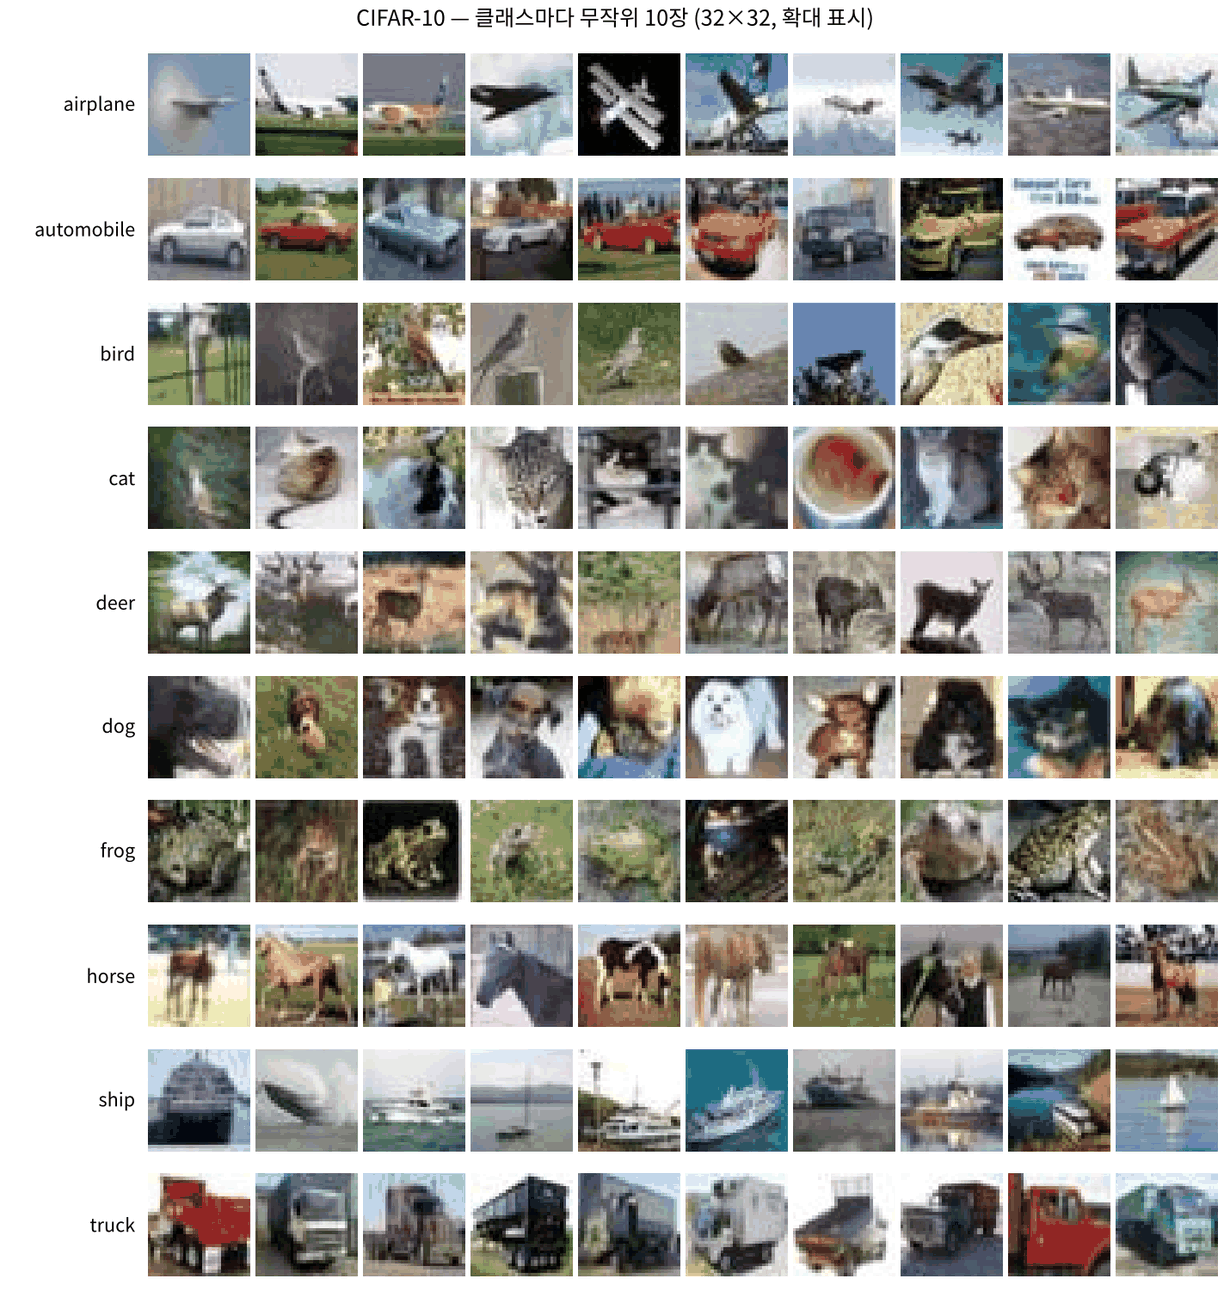

In [ ]:
#@title 🖼 그림 — CIFAR-10 의 10개 클래스 예시
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f1_cifar.png", embed=True, width=820))

같은 클래스 안에서도 색 · 배경 · 크기 · 자세가 크게 다릅니다. 모델은 이 변화를 견디는 **특징**을 배워야 합니다.

In [ ]:
plain_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
train_set = datasets.CIFAR10("data", train=True, download=True, transform=plain_tf)
test_set = datasets.CIFAR10("data", train=False, download=True, transform=plain_tf)
train_loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=NW, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False, num_workers=NW)

x0, y0 = train_set[0]
print(len(train_set), len(test_set), "| 한 장:", tuple(x0.shape), "| 레이블:", y0, CLASSES[y0])
print("원본 배열:", train_set.data.shape, train_set.data.dtype)    # (50000, 32, 32, 3) uint8 — HWC

**문제 1-1** 위에서 쓴 정규화 상수 `MEAN`, `STD` 는 어디서 왔을까요? train 원본 배열 `train_set.data` (50000, 32, 32, 3) uint8 에서 **채널별 평균 · 표준편차**를 직접 구하세요. 0~1 로 바꾼 뒤 채널 축(마지막 축) 을 남기고 나머지 축으로 평균합니다.

In [ ]:
data01 = train_set.data / 255.0
ch_mean = data01.mean(axis=____)
ch_std = data01.____
print("mean", ch_mean, "| std", ch_std)

In [ ]:
assert ch_mean.shape == (3,) and np.allclose(ch_mean, MEAN, atol=0.01) and np.allclose(ch_std, STD, atol=0.01); print("✅")

In [ ]:
#@title 🔒 정답 보기 1-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTEg4pSA4pSACmRhdGEwMSA9IHRyYWluX3NldC5kYXRhIC8gMjU1LjAKY2hfbWVhbiA9"
    "IGRhdGEwMS5tZWFuKGF4aXM9KDAsIDEsIDIpKQpjaF9zdGQgPSBkYXRhMDEuc3RkKGF4aXM9KDAsIDEsIDIpKQpw"
    "cmludCgibWVhbiIsIGNoX21lYW4sICJ8IHN0ZCIsIGNoX3N0ZCkKCvCfkqEg7ZW07ISkCmF4aXM9KDAsIDEsIDIp"
    "IOuKlCAo7J2066+47KeALCDshLjroZwsIOqwgOuhnCkg66W8IOuqqOuRkCDtj4nqt6DtlbQg7LGE64SQIDPqsJzr"
    "p4wg64Ko6rmB64uI64ukLiDsoJXqt5ztmZQg7IOB7IiY64qUICoqdHJhaW4g642w7J207YSw66Gc66eMKiog6rWs"
    "7ZWp64uI64ukIOKAlCB0ZXN0IOulvCDshJ7snLzrqbQg7Iuc7ZeYIOusuOygnOulvCDrr7jrpqwg67O4IOqyg+qz"
    "vCDqsJnsirXri4jri6Qu"
).decode("utf-8"))

**문제 1-2** CIFAR-10 용 MLP 를 만드세요: `3072 → 512 → 256 → 10`, 은닉층은 ReLU. 입력 한 장의 원소 수는 몇 개일까요?

In [ ]:
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(____, 512), nn.ReLU(),
    nn.Linear(512, 256), nn.ReLU(),
    nn.Linear(256, ____),
)
print("파라미터 수:", f"{count_params(mlp):,}")

In [ ]:
assert count_params(mlp) == 1_707_274 and mlp(torch.zeros(2, 3, 32, 32)).shape == (2, 10); print("✅")

In [ ]:
#@title 🔒 정답 보기 1-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTIg4pSA4pSACm1scCA9IG5uLlNlcXVlbnRpYWwoCiAgICBubi5GbGF0dGVuKCksCiAg"
    "ICBubi5MaW5lYXIoMyAqIDMyICogMzIsIDUxMiksIG5uLlJlTFUoKSwKICAgIG5uLkxpbmVhcig1MTIsIDI1Niks"
    "IG5uLlJlTFUoKSwKICAgIG5uLkxpbmVhcigyNTYsIDEwKSwKKQpwcmludCgi7YyM652866+47YSwIOyImDoiLCBm"
    "Intjb3VudF9wYXJhbXMobWxwKTosfSIpCgrwn5KhIO2VtOyEpAozMDcywrc1MTIgKyA1MTIgPSAxLDU3MywzNzYg"
    "wrcgNTEywrcyNTYgKyAyNTYgPSAxMzEsMzI4IMK3IDI1NsK3MTAgKyAxMCA9IDIsNTcwIOKGkiAxLDcwNywyNzQu"
    "IOyyqyDsuLUg7ZWY64KY6rCAIDkyJSDrpbwg7LCo7KeA7ZWp64uI64ukLg=="
).decode("utf-8"))

**문제 1-3** MLP 를 Adam(lr 0.001) 으로 **3 epoch** 학습하세요. 환경 셀의 `fit(model, train_loader, test_loader, epochs, opt)` 을 씁니다. (T4 GPU 로 epoch 당 약 10초)

In [ ]:
torch.manual_seed(0)
mlp = mlp.____
opt = torch.optim.Adam(mlp.parameters(), lr=1e-3)
hist_mlp = ____

In [ ]:
assert len(hist_mlp["test_acc"]) == 3 and hist_mlp["test_acc"][-1] > 0.4; print("✅ MLP test:", hist_mlp["test_acc"][-1])

In [ ]:
#@title 🔒 정답 보기 1-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAxLTMg4pSA4pSACnRvcmNoLm1hbnVhbF9zZWVkKDApCm1scCA9IG1scC50byhkZXZpY2Up"
    "Cm9wdCA9IHRvcmNoLm9wdGltLkFkYW0obWxwLnBhcmFtZXRlcnMoKSwgbHI9MWUtMykKaGlzdF9tbHAgPSBmaXQo"
    "bWxwLCB0cmFpbl9sb2FkZXIsIHRlc3RfbG9hZGVyLCAzLCBvcHQsIGxhYmVsPSJNTFAiKQoK8J+SoSDtlbTshKQK"
    "TU5JU1Qg7JeQ7IScIDk3JSDrpbwg64K0642YIOq1rOyhsOqwgCBDSUZBUi0xMCDsl5DshJzripQgNDkuOSUg7KCV"
    "64+E7JeQIOuouOutheuLiOuLpCAo7Iuk7ZaJIOyYiCkuIO2MjOudvOuvuO2EsOqwgCAxNzDrp4wg6rCc64KYIOuQ"
    "mOyngOunjCAn7J207JuDIO2UveyFgCcg7J20652864qUIOq1rOyhsOulvCDsk7Dsp4Ag66q77ZWY6riwIOuVjOus"
    "uOyeheuLiOuLpC4="
).decode("utf-8"))

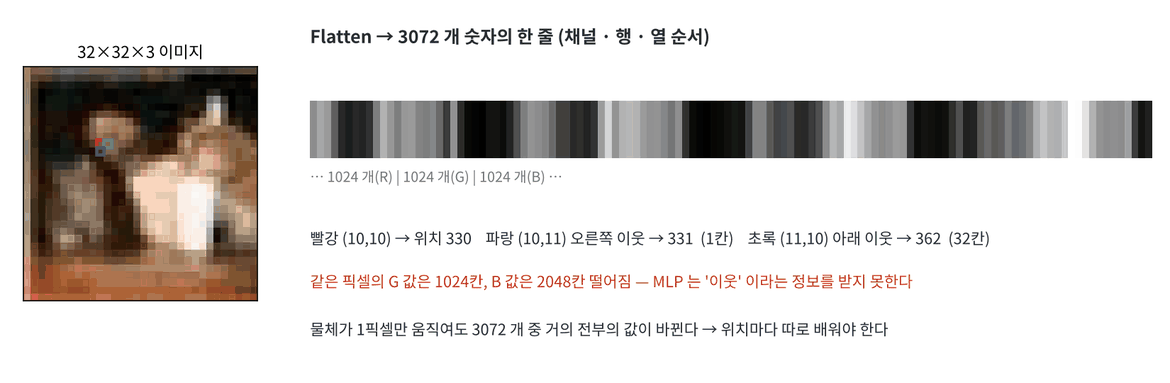

In [ ]:
#@title 🖼 그림 — 이미지를 펼치면 이웃 관계가 사라진다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f1_flatten.png", embed=True, width=780))

MLP 는 이미지를 3072 개 숫자의 줄로 펼칩니다. 바로 옆 픽셀이 줄에서는 32칸 · 1024칸 떨어지고, 물체가 한 칸만 옮겨 가도 전혀 다른 입력이 됩니다. **합성곱**은 작은 영역을 보는 필터를 이미지 전체에 **같은 가중치로** 밀고 다녀서 이 두 문제를 동시에 풉니다 (NN Day 5 — 지역성 · 가중치 공유).

| 모델 | 파라미터 | 3 epoch test (실행 예) |
|---|---|---|
| MLP 3072-512-256-10 | 1,707,274 | 0.4994 |
| LeNet-5 (3교시) | 62,006 | → 오늘 직접 확인 |
| ResNet-20 (8교시) | 272,474 | → 85% 이상 목표 |

#### ⚠️ 자주 하는 실수

- **GPU 를 안 켬** — 오늘은 학습량이 Day 1 의 수십 배입니다. `device : cpu` 이면 반드시 T4 GPU 로 바꾸세요.
- **test 데이터로 정규화 상수를 계산** — train 으로만 계산하고 test 에도 같은 값을 씁니다.
- **CIFAR-10 다운로드가 느림** — 첫 실행에 약 170 MB 를 받습니다. 1~2분 기다리세요.

#### 📌 1교시 정리

- CIFAR-10: 32×32×3 컬러, 10 클래스, train 50,000 · test 10,000.
- 정규화 상수 = train 데이터의 채널별 평균 · 표준편차.
- MLP 는 파라미터 170만 개로도 약 50% — 공간 구조를 버리기 때문.

## 2교시 — Conv 다시 보기: 출력 크기 · 파라미터 · 수용 영역

`nn.Conv2d(in_channels, out_channels, kernel_size, stride=1, padding=0, groups=1, bias=True)` 의 인자 하나하나가 **출력 크기 · 파라미터 수 · 연산량**을 정합니다. 오늘 만들 모든 모델은 이 세 가지 계산으로 설계됩니다.

> 🎬 **애니메이션** [D2-2 Conv2d 의 인자](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-2)
> 📝 **워크시트** [2교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t2)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

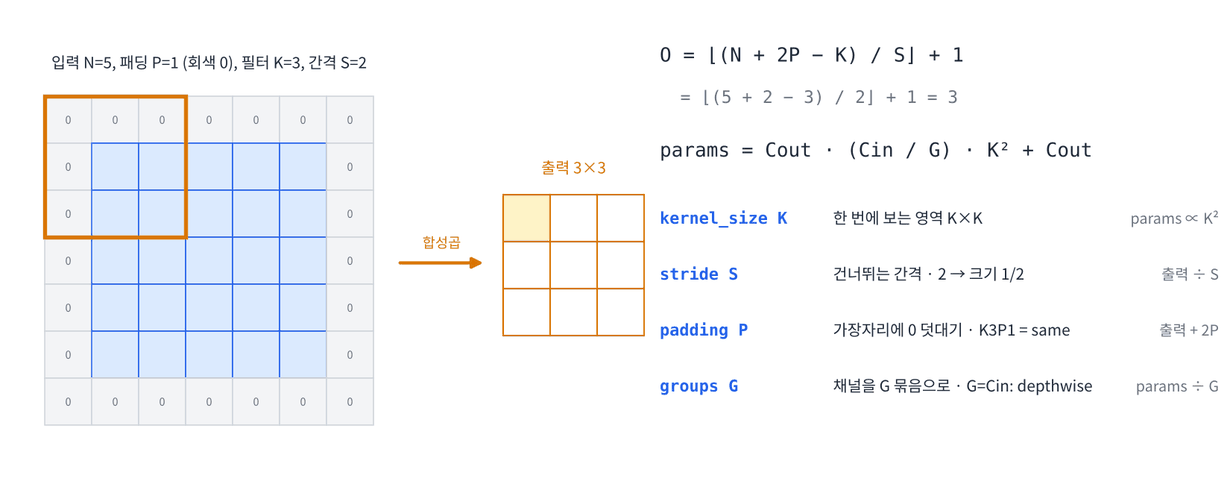

In [ ]:
#@title 🖼 그림 — Conv2d 의 인자와 출력 크기 · 파라미터 공식
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f2_conv.png", embed=True, width=820))

| 인자 | 하는 일 | 공식에서 |
|---|---|---|
| `kernel_size` K | 필터가 한 번에 보는 영역 K×K | 파라미터 ∝ K² |
| `stride` S | 필터가 건너뛰는 간격 — 2 면 출력이 절반 | 출력 ÷ S |
| `padding` P | 가장자리에 0 을 P 줄 덧댐 — K=3, P=1 이면 크기 유지 (same) | 출력 + 2P |
| `groups` G | 입력 채널을 G 묶음으로 나눠 따로 합성곱 — G = C 이면 **depthwise** (Day 3) | 파라미터 ÷ G |

$$O = \left\lfloor \frac{N + 2P - K}{S} \right\rfloor + 1 \qquad \text{params} = C_{out} \cdot \frac{C_{in}}{G} \cdot K^2 + C_{out}$$

**문제 2-1** 출력 크기 함수 `conv_out(n, k, s=1, p=0)` 을 완성하고 `nn.Conv2d` 의 실제 출력과 비교하세요.

In [ ]:
def conv_out(n, k, s=1, p=0):
    return ____

cases = [(32, 5, 1, 0), (32, 3, 1, 1), (32, 3, 2, 1), (28, 2, 2, 0), (224, 7, 2, 3), (7, 3, 2, 0)]
for n, k, s, p in cases:
    real = nn.Conv2d(1, 1, k, stride=s, padding=p)(torch.zeros(1, 1, n, n)).shape[-1]
    print(f"N={n:3d} K={k} S={s} P={p} → 공식 {conv_out(n, k, s, p):3d} | 실제 {real:3d}")

In [ ]:
assert all(conv_out(n, k, s, p) == nn.Conv2d(1, 1, k, stride=s, padding=p)(torch.zeros(1, 1, n, n)).shape[-1] for n, k, s, p in cases)
print("✅")

In [ ]:
#@title 🔒 정답 보기 2-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTEg4pSA4pSACmRlZiBjb252X291dChuLCBrLCBzPTEsIHA9MCk6CiAgICByZXR1cm4g"
    "KG4gKyAyICogcCAtIGspIC8vIHMgKyAxCgpjYXNlcyA9IFsoMzIsIDUsIDEsIDApLCAoMzIsIDMsIDEsIDEpLCAo"
    "MzIsIDMsIDIsIDEpLCAoMjgsIDIsIDIsIDApLCAoMjI0LCA3LCAyLCAzKSwgKDcsIDMsIDIsIDApXQpmb3Igbiwg"
    "aywgcywgcCBpbiBjYXNlczoKICAgIHJlYWwgPSBubi5Db252MmQoMSwgMSwgaywgc3RyaWRlPXMsIHBhZGRpbmc9"
    "cCkodG9yY2guemVyb3MoMSwgMSwgbiwgbikpLnNoYXBlWy0xXQogICAgcHJpbnQoZiJOPXtuOjNkfSBLPXtrfSBT"
    "PXtzfSBQPXtwfSDihpIg6rO17IudIHtjb252X291dChuLCBrLCBzLCBwKTozZH0gfCDsi6TsoJwge3JlYWw6M2R9"
    "IikKCvCfkqEg7ZW07ISkCi8vIOuKlCDrgrTrprwg64KY64iX7IWIIOKAlCDrgpjriITslrTrlqjslrTsp4Dsp4Ag"
    "7JWK7Jy866m0IOyYpOuluOyqvSDCtyDslYTrnpgg6rCA7J6l7J6Q66as6rCAIOuyhOugpOynkeuLiOuLpC4gKDIy"
    "NCwgNywgMiwgMykg4oaSIDExMiDripQgUmVzTmV0IOyyqyDsuLXsnZgg7ISk7KCV7J6F64uI64ukLg=="
).decode("utf-8"))

**문제 2-2** 파라미터 수 함수 `conv_params` 를 완성하세요. `groups` 가 있으면 필터 하나가 보는 입력 채널이 `cin // groups` 개로 줄어듭니다.

In [ ]:
def conv_params(cin, cout, k, groups=1, bias=True):
    w = cout * ____ * k * k
    return w + (____ if bias else 0)

tests = [(3, 6, 5, 1, True), (64, 128, 3, 1, True), (64, 64, 3, 64, True), (64, 128, 1, 1, False), (16, 32, 3, 1, False)]
for cin, cout, k, g, b in tests:
    real = count_params(nn.Conv2d(cin, cout, k, groups=g, bias=b))
    print(f"Conv2d({cin:3d}→{cout:3d}, {k}×{k}, groups={g:2d}, bias={b!s:5}) → 공식 {conv_params(cin, cout, k, g, b):7,} | 실제 {real:7,}")

In [ ]:
assert all(conv_params(c, o, k, g, b) == count_params(nn.Conv2d(c, o, k, groups=g, bias=b)) for c, o, k, g, b in tests); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTIg4pSA4pSACmRlZiBjb252X3BhcmFtcyhjaW4sIGNvdXQsIGssIGdyb3Vwcz0xLCBi"
    "aWFzPVRydWUpOgogICAgdyA9IGNvdXQgKiAoY2luIC8vIGdyb3VwcykgKiBrICogawogICAgcmV0dXJuIHcgKyAo"
    "Y291dCBpZiBiaWFzIGVsc2UgMCkKCnRlc3RzID0gWygzLCA2LCA1LCAxLCBUcnVlKSwgKDY0LCAxMjgsIDMsIDEs"
    "IFRydWUpLCAoNjQsIDY0LCAzLCA2NCwgVHJ1ZSksICg2NCwgMTI4LCAxLCAxLCBGYWxzZSksICgxNiwgMzIsIDMs"
    "IDEsIEZhbHNlKV0KZm9yIGNpbiwgY291dCwgaywgZywgYiBpbiB0ZXN0czoKICAgIHJlYWwgPSBjb3VudF9wYXJh"
    "bXMobm4uQ29udjJkKGNpbiwgY291dCwgaywgZ3JvdXBzPWcsIGJpYXM9YikpCiAgICBwcmludChmIkNvbnYyZCh7"
    "Y2luOjNkfeKGkntjb3V0OjNkfSwge2t9w5d7a30sIGdyb3Vwcz17ZzoyZH0sIGJpYXM9e2Ihczo1fSkg4oaSIOqz"
    "teyLnSB7Y29udl9wYXJhbXMoY2luLCBjb3V0LCBrLCBnLCBiKTo3LH0gfCDsi6TsoJwge3JlYWw6Nyx9IikKCvCf"
    "kqEg7ZW07ISkCmdyb3Vwcz02NCAoZGVwdGh3aXNlKSDripQg6rCZ7J2AIDY04oaSNjQgM8OXMyDsnbjrjbAg6rCA"
    "7KSR7LmY6rCAIDEvNjQgKGJpYXMg7Y+s7ZWoIDM2LDkyOCDihpIgNjQwLCDslb0gMS81OCkuIERheSAzIE1vYmls"
    "ZU5ldCDsnZgg7ZW17Ius7J6F64uI64ukLgpiaWFzPUZhbHNlIOuKlCDrsJTroZwg65Kk7JeQIEJhdGNoTm9ybSDs"
    "nbQg7JisIOuVjCDslIHri4jri6Qg4oCUIEJOIOydmCDOsiDqsIAgYmlhcyDsl63tlaDsnYQg7ZWY66+A66GcICg1"
    "6rWQ7IucKS4="
).decode("utf-8"))

### 수용 영역 (receptive field) — 출력 한 칸은 입력의 얼마만큼을 보는가

3×3 합성곱 한 층의 출력 한 칸은 입력 3×3 을 봅니다. 그 위에 3×3 을 한 번 더 쌓으면 출력 한 칸은 아래층 3×3 = 입력 **5×5** 를 봅니다. 층을 쌓을수록, 그리고 stride · pooling 으로 줄일수록 한 칸이 보는 영역이 넓어져 **작은 부품(에지) → 모양 → 물체**를 보게 됩니다.

계산 규칙 — 층마다 (커널 K, 간격 S):  `rf ← rf + (K − 1) × jump`,  `jump ← jump × S`  (시작: rf = 1, jump = 1)

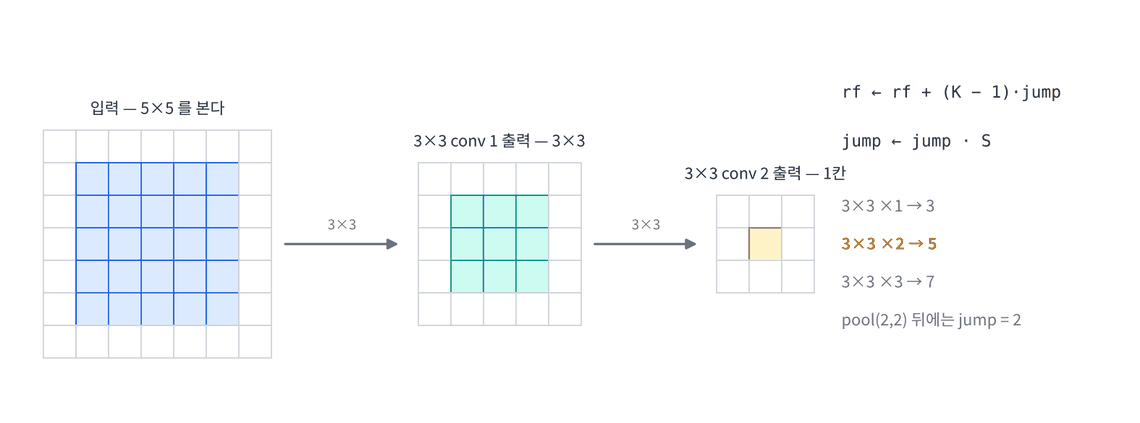

In [ ]:
#@title 🖼 그림 — 3×3 을 두 번 쌓으면 출력 한 칸이 입력 5×5 를 본다
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f2_rf.png", embed=True, width=760))

**문제 2-3** 수용 영역 함수 `receptive_field(layers)` 를 완성하세요. `layers` 는 (K, S) 의 리스트입니다.

In [ ]:
def receptive_field(layers):
    rf, jump = 1, 1
    for k, s in layers:
        rf = rf + ____
        jump = ____
    return rf

print("3×3 ×2      :", receptive_field([(3, 1)] * 2))
print("3×3 ×3      :", receptive_field([(3, 1)] * 3))
print("LeNet 5-2-5-2:", receptive_field([(5, 1), (2, 2), (5, 1), (2, 2)]))
print("3×3 ×2 → pool → 3×3 ×2 → pool → 3×3 ×2 (VGG 블록 3개):",
      receptive_field([(3, 1), (3, 1), (2, 2), (3, 1), (3, 1), (2, 2), (3, 1), (3, 1)]))

In [ ]:
assert receptive_field([(3, 1)] * 2) == 5 and receptive_field([(3, 1)] * 3) == 7
assert receptive_field([(5, 1), (2, 2), (5, 1), (2, 2)]) == 16
assert receptive_field([(3, 1), (3, 1), (2, 2), (3, 1), (3, 1), (2, 2), (3, 1), (3, 1)]) == 32
print("✅")

In [ ]:
#@title 🔒 정답 보기 2-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTMg4pSA4pSACmRlZiByZWNlcHRpdmVfZmllbGQobGF5ZXJzKToKICAgIHJmLCBqdW1w"
    "ID0gMSwgMQogICAgZm9yIGssIHMgaW4gbGF5ZXJzOgogICAgICAgIHJmID0gcmYgKyAoayAtIDEpICoganVtcAog"
    "ICAgICAgIGp1bXAgPSBqdW1wICogcwogICAgcmV0dXJuIHJmCgpwcmludCgiM8OXMyDDlzIgICAgICA6IiwgcmVj"
    "ZXB0aXZlX2ZpZWxkKFsoMywgMSldICogMikpCnByaW50KCIzw5czIMOXMyAgICAgIDoiLCByZWNlcHRpdmVfZmll"
    "bGQoWygzLCAxKV0gKiAzKSkKcHJpbnQoIkxlTmV0IDUtMi01LTI6IiwgcmVjZXB0aXZlX2ZpZWxkKFsoNSwgMSks"
    "ICgyLCAyKSwgKDUsIDEpLCAoMiwgMildKSkKcHJpbnQoIjPDlzMgw5cyIOKGkiBwb29sIOKGkiAzw5czIMOXMiDi"
    "hpIgcG9vbCDihpIgM8OXMyDDlzIgKFZHRyDruJTroZ0gM+qwnCk6IiwKICAgICAgcmVjZXB0aXZlX2ZpZWxkKFso"
    "MywgMSksICgzLCAxKSwgKDIsIDIpLCAoMywgMSksICgzLCAxKSwgKDIsIDIpLCAoMywgMSksICgzLCAxKV0pKQoK"
    "8J+SoSDtlbTshKQKcG9vbGluZygyLCAyKSDrkqTsl5DshJzripQganVtcCDqsIAgMiDqsIAg65CY7Ja0IOqwmeyd"
    "gCAzw5czIOydtCDsnoXroKXsl5DshJwg65GQIOuwsCDrhJPqsowg7Y287KeR64uI64ukLiA06rWQ7IucIFZHRy1t"
    "aW5pIOydmCDrp4jsp4Drp4kg7ZWp7ISx6rOx7J2AIDMyw5czMiDsnbTrr7jsp4Ag7KCE7LK0KOyImOyaqSDsmIHs"
    "l60gMzIpIOulvCDrtIXri4jri6Qg4oCUIOusvOyytCDsoITssrTrpbwg67O06rOgIO2MkOuLqO2VoCDsiJgg7J6I"
    "7Iq164uI64ukLg=="
).decode("utf-8"))

**문제 2-4** 설계 문제 — (N, 64, 32, 32) 를 받아 **(N, 128, 16, 16)** 을 내는 3×3 합성곱 한 층을 만드세요. 크기를 절반으로 줄이면서 채널을 두 배로 늘리는 것은 VGG · ResNet 의 공통 패턴입니다.

In [ ]:
down = nn.Conv2d(64, 128, kernel_size=3, stride=____, padding=____)
y = down(torch.zeros(2, 64, 32, 32))
print(tuple(y.shape))

In [ ]:
assert y.shape == (2, 128, 16, 16); print("✅")

In [ ]:
#@title 🔒 정답 보기 2-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAyLTQg4pSA4pSACmRvd24gPSBubi5Db252MmQoNjQsIDEyOCwga2VybmVsX3NpemU9Mywg"
    "c3RyaWRlPTIsIHBhZGRpbmc9MSkKeSA9IGRvd24odG9yY2guemVyb3MoMiwgNjQsIDMyLCAzMikpCnByaW50KHR1"
    "cGxlKHkuc2hhcGUpKQoK8J+SoSDtlbTshKQKKDMyICsgMsK3MSDiiJIgMykgLy8gMiArIDEgPSAxNi4g7YGs6riw"
    "6rCAIDEvMiDsnbQg65CY66m0IOychOy5mCDsiJjqsIAgMS80IOydtCDrkJjrr4DroZwg7LGE64SQ7J2EIDLrsLDr"
    "oZwg64qY66Ck64+EIOyXsOyCsOufieydgCDsoIjrsJjsnLzroZwg7KSE7Ja065Ot64uI64ukIOKAlCDsuLXrp4jr"
    "i6Qg7Jew7IKw65+J7J2EIOu5hOyKt+2VmOqyjCDrp57stpTripQg7ISk6rOELg=="
).decode("utf-8"))

#### 📌 2교시 정리

- 출력 크기 `(N + 2P − K) // S + 1`, 파라미터 `Cout · Cin/G · K² + Cout`.
- K=3 · P=1 · S=1 은 크기 유지, S=2 는 절반. groups = Cin 이면 depthwise (Day 3).
- 수용 영역은 층을 쌓고 크기를 줄일수록 넓어진다: 3×3 ×2 = 5×5, ×3 = 7×7.

## 3교시 — LeNet-5 · AlexNet

### LeNet-5 (1998) — 합성곱 신경망의 시작

Yann LeCun 이 우편번호 · 수표 손글씨를 읽으려고 만든 구조입니다. **Conv → Pool → Conv → Pool → FC → FC → FC** 의 뼈대는 지금도 그대로입니다. 원래는 32×32 흑백 입력 · tanh · 평균 풀링이었지만, 오늘은 CIFAR-10 컬러(3채널) 입력에 요즘 방식(ReLU · Max Pooling) 으로 만듭니다.

> 🎬 **애니메이션** [D2-3 LeNet-5 의 shape 흐름](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-3)
> 📝 **워크시트** [3교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t3)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

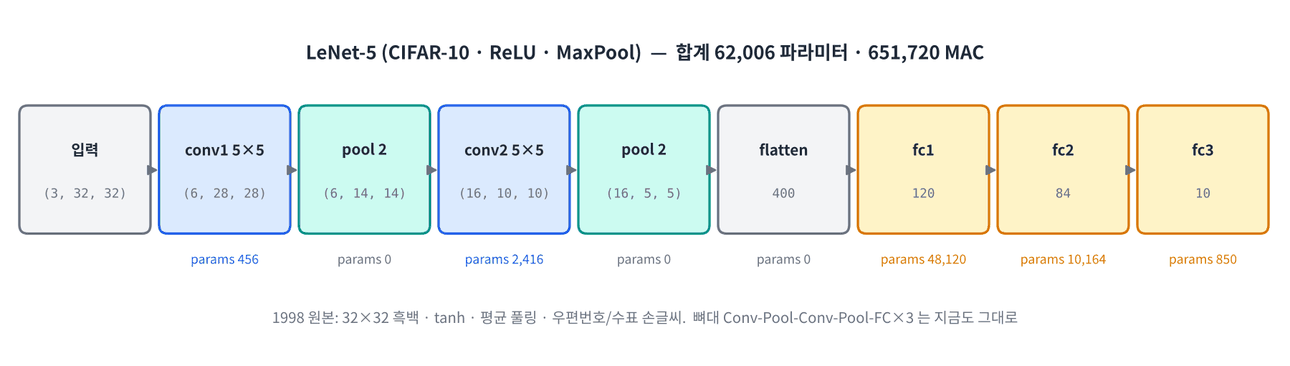

In [ ]:
#@title 🖼 그림 — LeNet-5 구조와 층별 shape · 파라미터
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f3_lenet.png", embed=True, width=860))

**문제 3-1** LeNet-5 를 `nn.Module` 로 만들고 파라미터 수가 **62,006** 인지 확인하세요. 그림의 shape 를 따라가며 `fc1` 의 입력 크기를 계산합니다.

In [ ]:
class LeNet5(nn.Module):
    def __init__(self, in_ch=3, n_cls=10):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, 6, 5)       # 32 → 28
        self.conv2 = nn.Conv2d(6, 16, ____)        # 14 → 10
        self.pool = nn.MaxPool2d(2)
        self.fc1 = nn.Linear(____, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, n_cls)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))      # (N, 6, 14, 14)
        x = self.pool(F.relu(____))    # (N, 16, 5, 5)
        x = x.flatten(1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

lenet = LeNet5()
print("파라미터 수:", f"{count_params(lenet):,}")

In [ ]:
assert count_params(lenet) == 62_006 and lenet(torch.zeros(2, 3, 32, 32)).shape == (2, 10); print("✅")

In [ ]:
#@title 🔒 정답 보기 3-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTEg4pSA4pSACmNsYXNzIExlTmV0NShubi5Nb2R1bGUpOgogICAgZGVmIF9faW5pdF9f"
    "KHNlbGYsIGluX2NoPTMsIG5fY2xzPTEwKToKICAgICAgICBzdXBlcigpLl9faW5pdF9fKCkKICAgICAgICBzZWxm"
    "LmNvbnYxID0gbm4uQ29udjJkKGluX2NoLCA2LCA1KSAgICAgICAjIDMyIOKGkiAyOAogICAgICAgIHNlbGYuY29u"
    "djIgPSBubi5Db252MmQoNiwgMTYsIDUpICAgICAgICAjIDE0IOKGkiAxMAogICAgICAgIHNlbGYucG9vbCA9IG5u"
    "Lk1heFBvb2wyZCgyKQogICAgICAgIHNlbGYuZmMxID0gbm4uTGluZWFyKDE2ICogNSAqIDUsIDEyMCkKICAgICAg"
    "ICBzZWxmLmZjMiA9IG5uLkxpbmVhcigxMjAsIDg0KQogICAgICAgIHNlbGYuZmMzID0gbm4uTGluZWFyKDg0LCBu"
    "X2NscykKCiAgICBkZWYgZm9yd2FyZChzZWxmLCB4KToKICAgICAgICB4ID0gc2VsZi5wb29sKEYucmVsdShzZWxm"
    "LmNvbnYxKHgpKSkgICAgICAjIChOLCA2LCAxNCwgMTQpCiAgICAgICAgeCA9IHNlbGYucG9vbChGLnJlbHUoc2Vs"
    "Zi5jb252Mih4KSkpICAgICMgKE4sIDE2LCA1LCA1KQogICAgICAgIHggPSB4LmZsYXR0ZW4oMSkKICAgICAgICB4"
    "ID0gRi5yZWx1KHNlbGYuZmMxKHgpKQogICAgICAgIHggPSBGLnJlbHUoc2VsZi5mYzIoeCkpCiAgICAgICAgcmV0"
    "dXJuIHNlbGYuZmMzKHgpCgpsZW5ldCA9IExlTmV0NSgpCnByaW50KCLtjIzrnbzrr7jthLAg7IiYOiIsIGYie2Nv"
    "dW50X3BhcmFtcyhsZW5ldCk6LH0iKQoK8J+SoSDtlbTshKQKY29udjEgM8K3NsK3MjUgKyA2ID0gNDU2IMK3IGNv"
    "bnYyIDbCtzE2wrcyNSArIDE2ID0gMiw0MTYgwrcgZmMxIDQwMMK3MTIwICsgMTIwID0gNDgsMTIwIMK3IGZjMiAx"
    "MCwxNjQgwrcgZmMzIDg1MCDihpIgNjIsMDA2LiBNTFAg7J2YIDEvMjcu"
).decode("utf-8"))

**문제 3-2** LeNet-5 를 MLP 와 같은 조건(Adam 0.001, 3 epoch) 으로 학습하세요. 파라미터가 1/27 인데 결과는?

In [ ]:
torch.manual_seed(0)
lenet = LeNet5().to(device)
opt = torch.optim.Adam(lenet.parameters(), lr=____)
hist_lenet = fit(lenet, train_loader, test_loader, ____, opt, label="LeNet")

In [ ]:
assert hist_lenet["test_acc"][-1] > hist_mlp["test_acc"][-1] - 0.02; print("✅ LeNet", hist_lenet["test_acc"][-1], "vs MLP", hist_mlp["test_acc"][-1])

In [ ]:
#@title 🔒 정답 보기 3-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTIg4pSA4pSACnRvcmNoLm1hbnVhbF9zZWVkKDApCmxlbmV0ID0gTGVOZXQ1KCkudG8o"
    "ZGV2aWNlKQpvcHQgPSB0b3JjaC5vcHRpbS5BZGFtKGxlbmV0LnBhcmFtZXRlcnMoKSwgbHI9MWUtMykKaGlzdF9s"
    "ZW5ldCA9IGZpdChsZW5ldCwgdHJhaW5fbG9hZGVyLCB0ZXN0X2xvYWRlciwgMywgb3B0LCBsYWJlbD0iTGVOZXQi"
    "KQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiDogTUxQIDAuNDk5NCAoMTcw66eMIO2MjOudvOuvuO2EsCkgdnMgTGVO"
    "ZXQtNSAwLjU0ODkgKDbrp4wg7YyM652866+47YSwKS4g6rCZ7J2AIDMgZXBvY2gg7JeQIO2MjOudvOuvuO2EsCAx"
    "LzI3IOuhnCDruYTsirftlZjqsbDrgpgg642UIOuGkuyKteuLiOuLpC4g7ZWp7ISx6rOx7J20ICfqs7XqsIQg6rWs"
    "7KGwJyDrpbwg6rO17Kec66GcIOyVjOqzoCDsi5zsnpHtlZjquLAg65WM66y47J6F64uI64ukIOKAlCDsnbTqsoPs"
    "nYQgKirqt4DrgqnsoIEg7Y647ZalIChpbmR1Y3RpdmUgYmlhcykqKiDsnbTrnbzqs6Ag7ZWp64uI64ukLg=="
).decode("utf-8"))

### AlexNet (2012) — 딥러닝의 귀환

ImageNet (1,000 클래스 · 학습 이미지 약 128만 장 · 224×224) 대회 ILSVRC 2012 에서 AlexNet 은 top-5 오류 **15.3%** 로, 2위(26.2%) 를 10%p 이상 앞섰습니다. 구조는 LeNet 을 크게 키운 것이지만, 지금 우리가 당연하게 쓰는 기법들이 여기서 자리 잡았습니다.

| 기법 | 이유 | 이 과정에서 |
|---|---|---|
| **ReLU** | sigmoid · tanh 보다 기울기 소실이 적고 계산이 빠름 | NN Day 2 |
| **Dropout** | 거대한 FC 층의 과적합 방지 | NN Day 4 |
| **데이터 증강** | 자르기 · 뒤집기로 학습 데이터를 부풀림 | 오늘 7교시 |
| **GPU 학습** | GTX 580 두 장으로 5~6일 학습 | 오늘 Colab T4 |

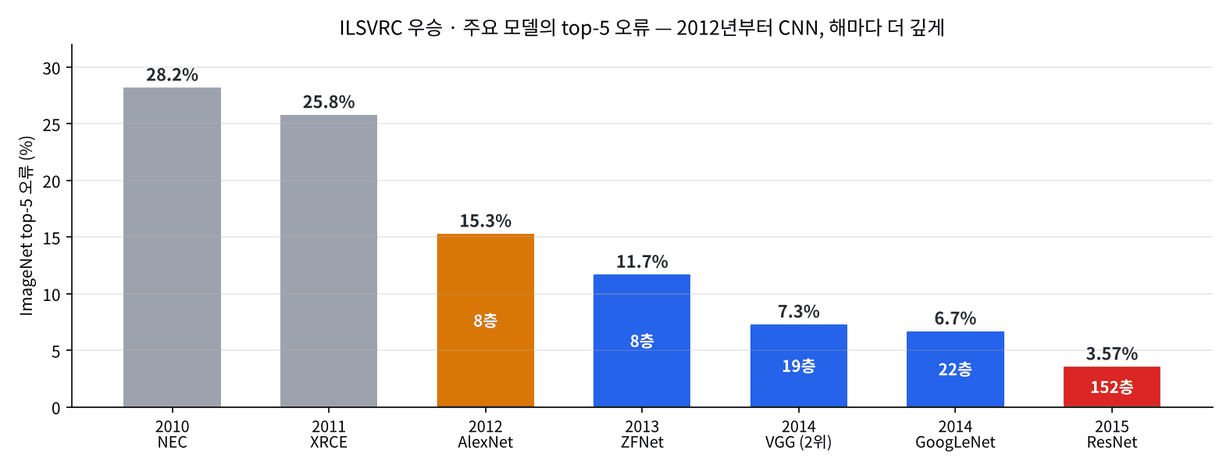

In [ ]:
#@title 🖼 그림 — ImageNet 대회 top-5 오류의 변화 (2010–2015)
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f3_imagenet.png", embed=True, width=820))

2012년 AlexNet 이후 우승 모델은 모두 CNN 이고, 해마다 **더 깊어졌습니다**: AlexNet 8층 → VGG 19층 → GoogLeNet 22층 → ResNet 152층. 오늘 4~6교시가 바로 이 흐름입니다.

**문제 3-3** torchvision 의 AlexNet 구조(가중치 없이) 를 만들어 전체 파라미터 수와 **가장 큰 층**을 찾으세요. `named_parameters()` 는 (이름, 텐서) 쌍을 돌려줍니다.

In [ ]:
alex = torchvision.models.alexnet(weights=None)
total = count_params(alex)
name, p = max(alex.____, key=lambda kv: kv[1].____)
print(f"전체 {total:,} | 가장 큰 텐서: {name} {tuple(p.shape)} = {p.numel():,} ({p.numel() / total:.1%})")

In [ ]:
assert total == 61_100_840 and name == "classifier.1.weight"; print("✅")

In [ ]:
#@title 🔒 정답 보기 3-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSAzLTMg4pSA4pSACmFsZXggPSB0b3JjaHZpc2lvbi5tb2RlbHMuYWxleG5ldCh3ZWlnaHRz"
    "PU5vbmUpCnRvdGFsID0gY291bnRfcGFyYW1zKGFsZXgpCm5hbWUsIHAgPSBtYXgoYWxleC5uYW1lZF9wYXJhbWV0"
    "ZXJzKCksIGtleT1sYW1iZGEga3Y6IGt2WzFdLm51bWVsKCkpCnByaW50KGYi7KCE7LK0IHt0b3RhbDosfSB8IOqw"
    "gOyepSDtgbAg7YWQ7IScOiB7bmFtZX0ge3R1cGxlKHAuc2hhcGUpfSA9IHtwLm51bWVsKCk6LH0gKHtwLm51bWVs"
    "KCkgLyB0b3RhbDouMSV9KSIpCgrwn5KhIO2VtOyEpApjbGFzc2lmaWVyLjEgPSBMaW5lYXIoOTIxNiDihpIgNDA5"
    "Nikg7ZWY64KY6rCAIDM3LDc0OCw3MzYg6rCc66GcIOyghOyytOydmCA2MS44JS4g7ZWp7ISx6rOxIDXsuLXsnYQg"
    "64ukIO2VqeyzkOuPhCAyLDQ2OSw2OTYg6rCcKDQuMCUpIOu/kOyeheuLiOuLpC4gJ+2MjOudvOuvuO2EsOuKlCBG"
    "QyDsl5AsIOyXsOyCsOydgCBDb252IOyXkCcg4oCUIE5OIERheSA1IOydmCDqsrDroaAg6re464yA66Gc7J206rOg"
    "LCDrkqTsnZgg66qo642465Ok7J2AIOydtCDqsbDrjIDtlZwgRkMg66W8IOykhOydtOuKlCDrsKntlqXsnLzroZwg"
    "6rCR64uI64ukIChSZXNOZXQg7J2AIEdBUCArIEZDIO2VmOuCmCku"
).decode("utf-8"))

#### 📌 3교시 정리

- LeNet-5: Conv-Pool-Conv-Pool-FC-FC-FC, 62,006 파라미터로 170만 파라미터 MLP 와 같거나 더 낫다 → 합성곱의 귀납적 편향.
- AlexNet 2012: ReLU · Dropout · 데이터 증강 · GPU, top-5 15.3%. 6,110만 파라미터 중 62% 가 FC 한 층.
- 이후 우승 모델은 계속 깊어진다 → 4교시 VGG.

## 4교시 — VGG: 3×3 을 쌓는 이유

VGG (2014, Oxford Visual Geometry Group) 의 아이디어는 단순합니다. **모든 합성곱을 3×3 으로 통일**하고, 같은 모양의 블록을 반복해 16~19층까지 쌓는다. 설계 규칙이 단순해서 지금도 '기본 CNN' 의 표준처럼 쓰입니다.

> 🎬 **애니메이션** [D2-4 3×3 쌓기와 수용 영역](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-4)
> 📝 **워크시트** [4교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t4)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

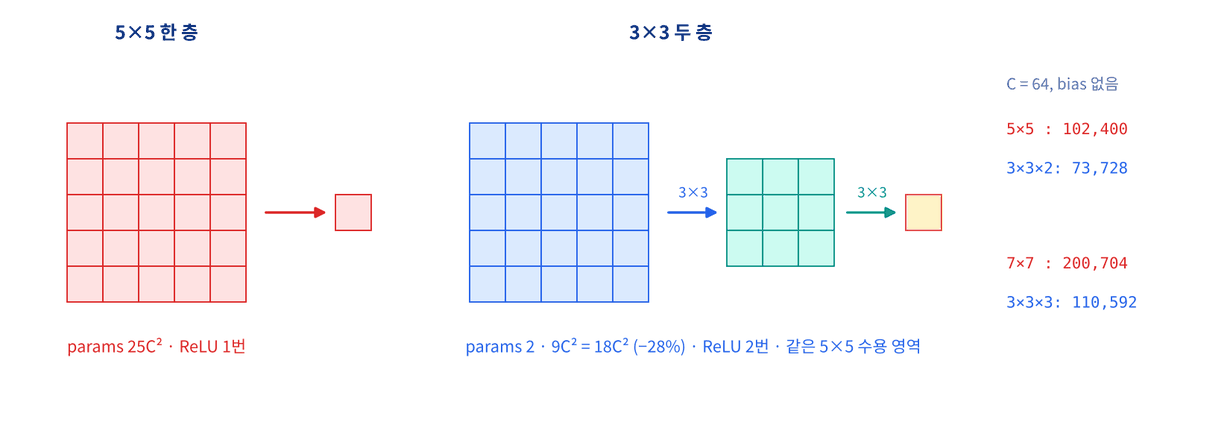

In [ ]:
#@title 🖼 그림 — 5×5 한 층 vs 3×3 두 층 — 같은 수용 영역, 적은 파라미터, 비선형 2번
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f4_3x3.png", embed=True, width=820))

3×3 두 층은 5×5 한 층과 **같은 5×5 영역**을 봅니다. 그런데

1. 파라미터가 적다: 2·9·C² = 18C² vs 25C² (28% 감소)
2. ReLU 가 두 번 들어가 더 복잡한 모양을 표현한다
3. 같은 원리로 3×3 세 층 = 7×7 한 층 (27C² vs 49C², 45% 감소)

**문제 4-1** 2교시의 `conv_params` 로 비교표를 완성하세요 (C = 64, bias 없음).

In [ ]:
C = 64
p5 = conv_params(C, C, 5, bias=False)
p33 = ____ * conv_params(C, C, 3, bias=False)
p7 = conv_params(C, C, 7, bias=False)
p333 = 3 * conv_params(C, C, ____, bias=False)
print(f"5×5 한 층 {p5:,} vs 3×3 두 층 {p33:,} ({1 - p33 / p5:.0%} 감소)")
print(f"7×7 한 층 {p7:,} vs 3×3 세 층 {p333:,} ({1 - p333 / p7:.0%} 감소)")

In [ ]:
assert (p5, p33, p7, p333) == (102_400, 73_728, 200_704, 110_592); print("✅")

In [ ]:
#@title 🔒 정답 보기 4-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTEg4pSA4pSACkMgPSA2NApwNSA9IGNvbnZfcGFyYW1zKEMsIEMsIDUsIGJpYXM9RmFs"
    "c2UpCnAzMyA9IDIgKiBjb252X3BhcmFtcyhDLCBDLCAzLCBiaWFzPUZhbHNlKQpwNyA9IGNvbnZfcGFyYW1zKEMs"
    "IEMsIDcsIGJpYXM9RmFsc2UpCnAzMzMgPSAzICogY29udl9wYXJhbXMoQywgQywgMywgYmlhcz1GYWxzZSkKcHJp"
    "bnQoZiI1w5c1IO2VnCDsuLUge3A1Oix9IHZzIDPDlzMg65GQIOy4tSB7cDMzOix9ICh7MSAtIHAzMyAvIHA1Oi4w"
    "JX0g6rCQ7IaMKSIpCnByaW50KGYiN8OXNyDtlZwg7Li1IHtwNzosfSB2cyAzw5czIOyEuCDsuLUge3AzMzM6LH0g"
    "KHsxIC0gcDMzMyAvIHA3Oi4wJX0g6rCQ7IaMKSIp"
).decode("utf-8"))

### VGG 블록 — `[Conv 3×3 → BN → ReLU] × n → MaxPool 2×2`

원래 VGG 에는 BatchNorm 이 없었지만(2015년에 나옴), 지금은 Conv 뒤에 BN 을 넣는 것이 표준입니다 — 5교시에서 이유를 봅니다. BN 이 bias 역할을 하므로 Conv 는 `bias=False`.

CIFAR-10 용 **VGG-mini**: 블록 3개 (채널 32 → 64 → 128, 블록마다 합성곱 2개) → (N, 128, 4, 4) → Flatten → Linear(2048 → 10).

**문제 4-2** `vgg_block` 과 VGG-mini 를 완성하세요.

In [ ]:
def vgg_block(cin, cout, n_convs):
    layers = []
    for i in range(n_convs):
        layers += [nn.Conv2d(cin if i == 0 else cout, cout, 3, padding=____, bias=False),
                   nn.BatchNorm2d(____),
                   nn.ReLU(inplace=True)]
    layers.append(nn.MaxPool2d(2))
    return nn.Sequential(*layers)

def vgg_mini(n_cls=10):
    return nn.Sequential(
        vgg_block(3, 32, 2),        # (N, 32, 16, 16)
        vgg_block(32, 64, 2),       # (N, 64, 8, 8)
        vgg_block(64, ____, 2),    # (N, 128, 4, 4)
        nn.Flatten(),
        nn.Linear(____, n_cls),
    )

vgg = vgg_mini()
print("파라미터 수:", f"{count_params(vgg):,}", "| 출력:", tuple(vgg(torch.zeros(2, 3, 32, 32)).shape))

In [ ]:
assert vgg(torch.zeros(2, 3, 32, 32)).shape == (2, 10) and count_params(vgg) == 307_946; print("✅")

In [ ]:
#@title 🔒 정답 보기 4-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTIg4pSA4pSACmRlZiB2Z2dfYmxvY2soY2luLCBjb3V0LCBuX2NvbnZzKToKICAgIGxh"
    "eWVycyA9IFtdCiAgICBmb3IgaSBpbiByYW5nZShuX2NvbnZzKToKICAgICAgICBsYXllcnMgKz0gW25uLkNvbnYy"
    "ZChjaW4gaWYgaSA9PSAwIGVsc2UgY291dCwgY291dCwgMywgcGFkZGluZz0xLCBiaWFzPUZhbHNlKSwKICAgICAg"
    "ICAgICAgICAgICAgIG5uLkJhdGNoTm9ybTJkKGNvdXQpLAogICAgICAgICAgICAgICAgICAgbm4uUmVMVShpbnBs"
    "YWNlPVRydWUpXQogICAgbGF5ZXJzLmFwcGVuZChubi5NYXhQb29sMmQoMikpCiAgICByZXR1cm4gbm4uU2VxdWVu"
    "dGlhbCgqbGF5ZXJzKQoKZGVmIHZnZ19taW5pKG5fY2xzPTEwKToKICAgIHJldHVybiBubi5TZXF1ZW50aWFsKAog"
    "ICAgICAgIHZnZ19ibG9jaygzLCAzMiwgMiksICAgICAgICAjIChOLCAzMiwgMTYsIDE2KQogICAgICAgIHZnZ19i"
    "bG9jaygzMiwgNjQsIDIpLCAgICAgICAjIChOLCA2NCwgOCwgOCkKICAgICAgICB2Z2dfYmxvY2soNjQsIDEyOCwg"
    "MiksICAgICMgKE4sIDEyOCwgNCwgNCkKICAgICAgICBubi5GbGF0dGVuKCksCiAgICAgICAgbm4uTGluZWFyKDEy"
    "OCAqIDQgKiA0LCBuX2NscyksCiAgICApCgp2Z2cgPSB2Z2dfbWluaSgpCnByaW50KCLtjIzrnbzrr7jthLAg7IiY"
    "OiIsIGYie2NvdW50X3BhcmFtcyh2Z2cpOix9IiwgInwg7Lac66ClOiIsIHR1cGxlKHZnZyh0b3JjaC56ZXJvcygy"
    "LCAzLCAzMiwgMzIpKS5zaGFwZSkpCgrwn5KhIO2VtOyEpArtlanshLHqs7EgNuy4tShiaWFzIOyXhuydjCkgMjg2"
    "LDU2MCArIEJOIDbqsJwgODk2ICsgTGluZWFyIDIwLDQ5MCA9IDMwNyw5NDYg7YyM652866+47YSwLiBMZU5ldC01"
    "IOydmCA167CwLCBNTFAg7J2YIDEvNS41Lg=="
).decode("utf-8"))

**문제 4-3** VGG-mini 를 같은 조건(Adam 0.001, 3 epoch) 으로 학습하세요. (T4 GPU 로 epoch 당 약 15초)

In [ ]:
torch.manual_seed(0)
vgg = vgg_mini().____
opt = torch.optim.Adam(vgg.parameters(), lr=1e-3)
hist_vgg = ____

In [ ]:
assert hist_vgg["test_acc"][-1] > hist_lenet["test_acc"][-1]; print("✅ VGG-mini", hist_vgg["test_acc"][-1])

In [ ]:
#@title 🔒 정답 보기 4-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA0LTMg4pSA4pSACnRvcmNoLm1hbnVhbF9zZWVkKDApCnZnZyA9IHZnZ19taW5pKCkudG8o"
    "ZGV2aWNlKQpvcHQgPSB0b3JjaC5vcHRpbS5BZGFtKHZnZy5wYXJhbWV0ZXJzKCksIGxyPTFlLTMpCmhpc3Rfdmdn"
    "ID0gZml0KHZnZywgdHJhaW5fbG9hZGVyLCB0ZXN0X2xvYWRlciwgMywgb3B0LCBsYWJlbD0iVkdHLW1pbmkiKQoK"
    "8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiDogVkdHLW1pbmkgMyBlcG9jaCB0ZXN0IDAuNzUyNiDigJQgTGVOZXQtNSAw"
    "LjU0ODkg67O064ukIO2BrOqyjCDrhpLsirXri4jri6QuIOq5iuydtCjtlanshLHqs7EgNuy4tSkgwrcgM8OXMyDC"
    "tyBCTiDsnZgg7Zqo6rO87J6F64uI64ukLg=="
).decode("utf-8"))

In [ ]:
plt.figure(figsize=(6, 3.5))
for h, lab in [(hist_mlp, "MLP"), (hist_lenet, "LeNet-5"), (hist_vgg, "VGG-mini")]:
    plt.plot(range(1, 4), h["test_acc"], "o-", label=lab)
plt.xlabel("epoch"); plt.ylabel("test accuracy"); plt.xticks([1, 2, 3]); plt.grid(alpha=.3); plt.legend(); plt.title("CIFAR-10, Adam 1e-3")
plt.show()

#### 📌 4교시 정리

- 3×3 두 층 = 5×5 수용 영역, 파라미터 28% 적고 비선형 2번. 세 층 = 7×7, 45% 적다.
- VGG 블록 = [Conv3×3-BN-ReLU] × n + MaxPool. 크기 1/2 마다 채널 2배.
- 깊게 쌓으면 좋아진다 — 그럼 끝없이 쌓으면? → 5교시.

## 5교시 — 깊이의 문제 · BatchNorm

VGG 가 깊이로 성공했으니 층을 더 쌓으면 더 좋아질까요? 실험해 봅니다. 크기를 줄이지 않는 단순한 합성곱 망 **plain-N** 을 만듭니다: 3×3 Conv 를 N−1 개 쌓고 → 전역 평균 풀링(GAP) → Linear(16 → 10). 채널은 모두 16.

> 🎬 **애니메이션** [D2-5 기울기 소실과 BatchNorm](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-5)
> 📝 **워크시트** [5교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t5)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

In [ ]:
def plain_net(depth, bn=False, width=16):
    """3×3 Conv (depth-1)개 + GAP + Linear — 가중치 층 depth 개"""
    layers, cin = [], 3
    for _ in range(depth - 1):
        layers.append(nn.Conv2d(cin, width, 3, padding=1, bias=not bn))
        if bn:
            layers.append(nn.BatchNorm2d(width))
        layers.append(nn.ReLU(inplace=True))
        cin = width
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10)]
    return nn.Sequential(*layers)

for d in (8, 20):
    print(f"plain-{d}: 파라미터 {count_params(plain_net(d)):,}")

**문제 5-1** 학습 전 망에 배치 하나를 넣고 역전파했을 때, **층마다 가중치 기울기의 크기(노름)** 를 구하세요. 출력 쪽에서 입력 쪽으로 갈수록 기울기가 어떻게 변하는지 봅니다.

In [ ]:
def conv_grad_norms(net, xb, yb):
    net.zero_grad()
    F.cross_entropy(net(xb), yb).backward()
    return [m.weight.____.norm().item() for m in net.modules() if isinstance(m, ____)]

xb, yb = next(iter(DataLoader(train_set, batch_size=128, shuffle=True)))
torch.manual_seed(0)
g8, g20 = conv_grad_norms(plain_net(8), xb, yb), conv_grad_norms(plain_net(20), xb, yb)
torch.manual_seed(0)
g20bn = conv_grad_norms(plain_net(20, bn=True), xb, yb)
print(f"plain-8      첫 층 {g8[0]:.2e} | 마지막 층 {g8[-1]:.2e}")
print(f"plain-20     첫 층 {g20[0]:.2e} | 마지막 층 {g20[-1]:.2e}")
print(f"plain-20 +BN 첫 층 {g20bn[0]:.2e} | 마지막 층 {g20bn[-1]:.2e}")

In [ ]:
assert len(g8) == 7 and len(g20) == 19 and g20[0] < g8[0]; print("✅")
plt.figure(figsize=(7, 3.5))
plt.semilogy(range(1, 8), g8, "o-", label="plain-8")
plt.semilogy(range(1, 20), g20, "o-", label="plain-20")
plt.semilogy(range(1, 20), g20bn, "s-", label="plain-20 + BN")
plt.xlabel("conv layer (1 = input side)"); plt.ylabel("weight grad norm (log)"); plt.grid(alpha=.3, which="both"); plt.legend(); plt.show()

In [ ]:
#@title 🔒 정답 보기 5-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTEg4pSA4pSACmRlZiBjb252X2dyYWRfbm9ybXMobmV0LCB4YiwgeWIpOgogICAgbmV0"
    "Lnplcm9fZ3JhZCgpCiAgICBGLmNyb3NzX2VudHJvcHkobmV0KHhiKSwgeWIpLmJhY2t3YXJkKCkKICAgIHJldHVy"
    "biBbbS53ZWlnaHQuZ3JhZC5ub3JtKCkuaXRlbSgpIGZvciBtIGluIG5ldC5tb2R1bGVzKCkgaWYgaXNpbnN0YW5j"
    "ZShtLCBubi5Db252MmQpXQoKeGIsIHliID0gbmV4dChpdGVyKERhdGFMb2FkZXIodHJhaW5fc2V0LCBiYXRjaF9z"
    "aXplPTEyOCwgc2h1ZmZsZT1UcnVlKSkpCnRvcmNoLm1hbnVhbF9zZWVkKDApCmc4LCBnMjAgPSBjb252X2dyYWRf"
    "bm9ybXMocGxhaW5fbmV0KDgpLCB4YiwgeWIpLCBjb252X2dyYWRfbm9ybXMocGxhaW5fbmV0KDIwKSwgeGIsIHli"
    "KQp0b3JjaC5tYW51YWxfc2VlZCgwKQpnMjBibiA9IGNvbnZfZ3JhZF9ub3JtcyhwbGFpbl9uZXQoMjAsIGJuPVRy"
    "dWUpLCB4YiwgeWIpCnByaW50KGYicGxhaW4tOCAgICAgIOyyqyDsuLUge2c4WzBdOi4yZX0gfCDrp4jsp4Drp4kg"
    "7Li1IHtnOFstMV06LjJlfSIpCnByaW50KGYicGxhaW4tMjAgICAgIOyyqyDsuLUge2cyMFswXTouMmV9IHwg66eI"
    "7KeA66eJIOy4tSB7ZzIwWy0xXTouMmV9IikKcHJpbnQoZiJwbGFpbi0yMCArQk4g7LKrIOy4tSB7ZzIwYm5bMF06"
    "LjJlfSB8IOuniOyngOuniSDsuLUge2cyMGJuWy0xXTouMmV9IikKCvCfkqEg7ZW07ISkCuyLpO2WiSDsmIg6IOyy"
    "qyDsuLUg6riw7Jq46riwIHBsYWluLTggMy4yZS0wNCwgcGxhaW4tMjAgMS4xZS0wOSAo66eI7KeA66eJIOy4tSAy"
    "LjJlLTAyIOydmCDslb0gMuyynOunjOu2hOydmCAxKSwgcGxhaW4tMjArQk4gMy40ZS0wMS4gcGxhaW4tMjAgKEJO"
    "IOyXhuydjCkg7J2AIOyeheugpSDsqr0g7Li17Jy866GcIOqwiOyImOuhnSDquLDsmrjquLDqsIAg6riw7ZWY6riJ"
    "7IiY7KCB7Jy866GcIOyekeyVhOynkeuLiOuLpCDigJQgKirquLDsmrjquLAg7IaM7IukICh2YW5pc2hpbmcgZ3Jh"
    "ZGllbnQpKiouIOyXreyghO2MjOuKlCDsuLXrp4jri6Qg6rCA7KSR7LmY7JmAIOq1reyGjCDrr7jrtoTsnYQg6rOx"
    "7ZWY64qU642wLCDqt7gg7YGs6riw6rCAIDEg67O064ukIOyhsOq4iOunjCDsnpHslYTrj4QgMTnrsogg6rOx7ZWY"
    "66m0IDAg7JeQIOqwgOq5jOybjOynkeuLiOuLpC4gQk4g7J2EIOuEo+ycvOuptCDsuLXrp4jri6Qg7YGs6riw6rCA"
    "IOuLpOyLnCDrp57strDsoLgg6riw7Jq46riw6rCAIOqzoOultOqyjCDtnZDrpoXri4jri6Qu"
).decode("utf-8"))

### 학습으로 확인 — 깊으면 더 좋은가?

시간을 아끼려고 train 앞 **10,000 장**만 쓰고, SGD(lr 0.05, momentum 0.9) 로 **3 epoch** 학습합니다. (네 모델 합쳐 T4 로 약 1분)

**문제 5-2** plain-8 · plain-20 을 BN 없이 / 있이 학습해 마지막 train 손실과 test 정확도를 비교하세요. 학습 데이터 일부를 쓰는 `Subset(데이터셋, 인덱스)` 를 씁니다.

In [ ]:
small_loader = DataLoader(Subset(train_set, range(____)), batch_size=128, shuffle=True, num_workers=NW)
depth_hist = {}
for d in (8, 20):
    for bn in (False, True):
        torch.manual_seed(0)
        net = plain_net(d, bn=____).to(device)
        opt = torch.optim.SGD(net.parameters(), lr=0.05, momentum=0.9)
        depth_hist[(d, bn)] = fit(net, small_loader, test_loader, 3, opt, label=f"plain-{d:2d} BN={bn!s:5}")

In [ ]:
assert len(depth_hist) == 4
print(f"{'모델':14s} {'train loss':>10s} {'test acc':>9s}")
for (d, bn), h in depth_hist.items():
    print(f"plain-{d:<2d} BN={bn!s:5} {h['loss'][-1]:10.4f} {h['test_acc'][-1]:9.4f}")
print("✅")

In [ ]:
#@title 🔒 정답 보기 5-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTIg4pSA4pSACnNtYWxsX2xvYWRlciA9IERhdGFMb2FkZXIoU3Vic2V0KHRyYWluX3Nl"
    "dCwgcmFuZ2UoMTAwMDApKSwgYmF0Y2hfc2l6ZT0xMjgsIHNodWZmbGU9VHJ1ZSwgbnVtX3dvcmtlcnM9TlcpCmRl"
    "cHRoX2hpc3QgPSB7fQpmb3IgZCBpbiAoOCwgMjApOgogICAgZm9yIGJuIGluIChGYWxzZSwgVHJ1ZSk6CiAgICAg"
    "ICAgdG9yY2gubWFudWFsX3NlZWQoMCkKICAgICAgICBuZXQgPSBwbGFpbl9uZXQoZCwgYm49Ym4pLnRvKGRldmlj"
    "ZSkKICAgICAgICBvcHQgPSB0b3JjaC5vcHRpbS5TR0QobmV0LnBhcmFtZXRlcnMoKSwgbHI9MC4wNSwgbW9tZW50"
    "dW09MC45KQogICAgICAgIGRlcHRoX2hpc3RbKGQsIGJuKV0gPSBmaXQobmV0LCBzbWFsbF9sb2FkZXIsIHRlc3Rf"
    "bG9hZGVyLCAzLCBvcHQsIGxhYmVsPWYicGxhaW4te2Q6MmR9IEJOPXtibiFzOjV9IikKCvCfkqEg7ZW07ISkCuyL"
    "pO2WiSDsmIggKOuniOyngOuniSBlcG9jaCwgdHJhaW4g7IaQ7IukIC8gdGVzdCk6Cgp8IHwgQk4g7JeG7J2MIHwg"
    "Qk4g7J6I7J2MIHwKfC0tLXwtLS18LS0tfAp8IHBsYWluLTggfCAyLjMwNCAvIDAuMTAwIHwgMS42OTkgLyAwLjMw"
    "NCB8CnwgcGxhaW4tMjAgfCAyLjMwMyAvIDAuMTAwIHwgMS43ODUgLyAwLjI3MCB8CgoxLiAqKkJOIOydtCDsl4bs"
    "nLzrqbQgOOy4teyhsOywqCoqIOyGkOyLpOydtCAyLjMwICg9IGxuIDEwLCDssI3quLApIOyXkOyEnCDsm4Dsp4Hs"
    "nbTsp4Ag7JWK7Iq164uI64ukLiBQeVRvcmNoIOq4sOuzuCDstIjquLDtmZTroZwg7Li17J2EIOyMk+ycvOuptCDs"
    "i6DtmLjsmYAg6riw7Jq46riw6rCAIOy4teuniOuLpCDsnpHslYTsp4DquLAg65WM66y47J6F64uI64ukICg1LTEg"
    "7JeQ7IScIHBsYWluLTgg7LKrIOy4teuPhCDrp4jsp4Drp4kg7Li17J2YIOyVvSAxLzEwMCkuCjIuICoqQk4g7J2E"
    "IOuEo+ycvOuptCDrkZgg64ukIOuwsOybgeuLiOuLpC4qKiDqt7jrn7DrjbAgMjDsuLXsnbQgOOy4teuztOuLpCAq"
    "KnRyYWluIOyGkOyLpOyhsOywqCDrhpLsirXri4jri6QqKiDigJQg6rO87KCB7ZWpKHRyYWluIOydgCDsoovqs6Ag"
    "dGVzdCDrp4wg64KY7IGoKSDsnbQg7JWE64uI6528IOq5iuydgCDrp53snZgg7LWc7KCB7ZmUIOyekOyytOqwgCDs"
    "lrTroKTsmrQg6rKD7J6F64uI64ukLiDsnbTqsoPsnbQgNuq1kOyLnOydmCAqKuyEseuKpSDsoIDtlZggKGRlZ3Jh"
    "ZGF0aW9uKSoqIOyeheuLiOuLpC4="
).decode("utf-8"))

### BatchNorm 다시 보기 — NN Day 4 의 그 BN

| | NN Day 4 `BatchNorm` (Affine 뒤) | `nn.BatchNorm2d(C)` (Conv 뒤) |
|---|---|---|
| 평균 · 분산을 내는 축 | 배치 (axis=0) | 배치 · 세로 · 가로 (채널마다 하나) |
| 학습 파라미터 | γ, β (특징 수만큼) | γ, β 각 **C 개** |
| 추론 때 | running 평균 · 분산 | 같음 — `model.eval()` 이 전환 |

$$\hat{x} = \frac{x - \mu_{\text{batch}}}{\sqrt{\sigma^2_{\text{batch}} + \epsilon}}, \qquad y = \gamma \hat{x} + \beta$$

층마다 출력 분포를 평균 0 · 분산 1 근처로 다시 맞춰 주므로, 기울기가 층을 지나며 계속 작아지거나 커지는 것을 막습니다. 큰 학습률도 견뎌 학습이 빨라집니다.

**문제 5-3** `nn.BatchNorm2d(16)` 의 **학습 파라미터 수**와 `state_dict()` 에 저장되는 항목을 확인하세요. 학습되지 않지만 저장되는 값을 **buffer** 라고 합니다.

In [ ]:
bn16 = nn.BatchNorm2d(16)
n_learn = ____
keys = list(bn16.state_dict().keys())
print("학습 파라미터:", n_learn, "| state_dict:", keys)

In [ ]:
assert n_learn == 32 and keys == ["weight", "bias", "running_mean", "running_var", "num_batches_tracked"]; print("✅")

In [ ]:
#@title 🔒 정답 보기 5-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA1LTMg4pSA4pSACmJuMTYgPSBubi5CYXRjaE5vcm0yZCgxNikKbl9sZWFybiA9IGNvdW50"
    "X3BhcmFtcyhibjE2KQprZXlzID0gbGlzdChibjE2LnN0YXRlX2RpY3QoKS5rZXlzKCkpCnByaW50KCLtlZnsirUg"
    "7YyM652866+47YSwOiIsIG5fbGVhcm4sICJ8IHN0YXRlX2RpY3Q6Iiwga2V5cykKCvCfkqEg7ZW07ISkCndlaWdo"
    "dCA9IM6zLCBiaWFzID0gzrIgKOqwgSAxNuqwnCDihpIgMzLqsJwpLiBydW5uaW5nX21lYW4gwrcgcnVubmluZ192"
    "YXIg64qUIO2VmeyKtSDspJEg7KeA7IiYIOydtOuPmSDtj4nqt6DsnLzroZwg7IyT7J2064qUIGJ1ZmZlciDroZws"
    "IOy2lOuhoCDrlYwg7JSB64uI64ukLiDqt7jrnpjshJwg7KCA7J6lIMK3IOu2iOufrOyYpOq4sOyXkCDtlajqu5gg"
    "65Ok7Ja06rCA7JW8IO2VqeuLiOuLpC4="
).decode("utf-8"))

#### ⚠️ 자주 하는 실수

- 추론할 때 `model.eval()` 을 빼먹음 → BN 이 test 배치의 평균을 써서 결과가 배치마다 달라집니다.
- 배치 크기 1 로 BN 학습 → 분산을 구할 수 없어 오류 또는 불안정. 배치는 충분히 크게.
- BN 앞 Conv 에 `bias=True` → 오류는 없지만 β 와 겹쳐 파라미터 낭비.

#### 📌 5교시 정리

- 그냥 깊게 쌓으면 입력 쪽 기울기가 사라진다 (기울기 소실) → BN 없는 plain 망은 8층조차 3 epoch 동안 못 배웠다.
- BatchNorm: 채널마다 배치 통계로 정규화 + γ, β. 기울기가 고르게 흐르고 큰 학습률을 견딘다.
- BN 이 있어도 20층이 8층보다 train 손실이 높다 (성능 저하, degradation) → 6교시 ResNet.

## 6교시 — ResNet: Residual block

2015년 Kaiming He 등은 BN 을 넣어도 **56층 plain 망이 20층보다 train 오류가 높은** 현상(성능 저하, degradation) 을 보였습니다. 깊은 망이 최소한 얕은 망만큼은 해야 정상입니다 — 남는 층이 그냥 '아무것도 안 하면(항등 함수)' 되니까요. 그런데 여러 층을 거쳐 정확히 항등 함수를 배우는 것이 의외로 어렵습니다.

**해법: 입력을 출력에 그대로 더해 주는 지름길 (skip connection)**. 층들은 '입력에서 얼마나 바꿀지(잔차, residual)' 만 배우면 되고, 바꿀 게 없으면 0 을 배우면 됩니다.

$$y = \mathrm{ReLU}\big(F(x) + x\big)$$

> 🎬 **애니메이션** [D2-6 Residual 지름길](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-6)
> 📝 **워크시트** [6교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t6)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

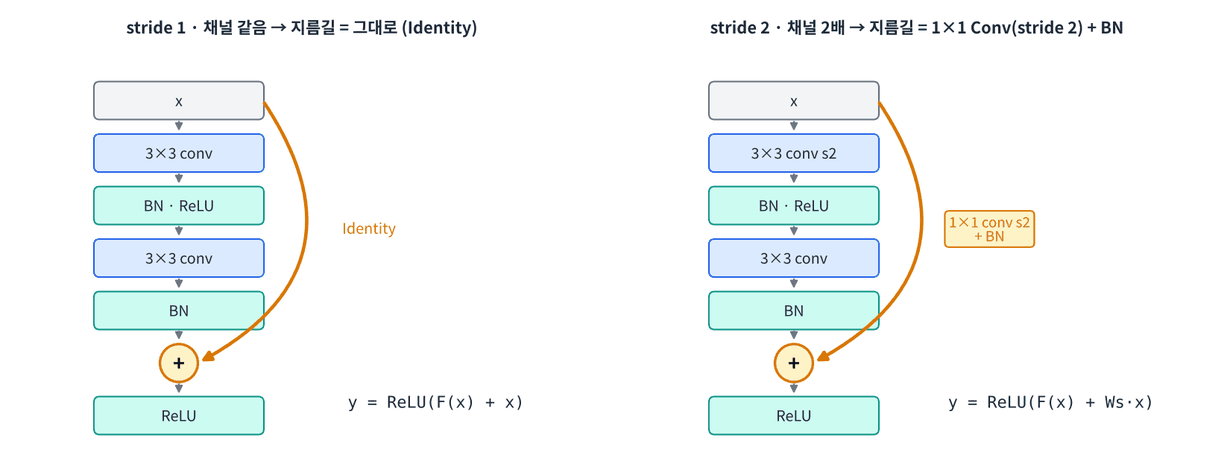

In [ ]:
#@title 🖼 그림 — BasicBlock — 3×3 Conv 두 번 + 지름길, 크기가 바뀌면 1×1 Conv 지름길
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f6_block.png", embed=True, width=820))

역전파에서 덧셈 노드는 기울기를 **그대로 두 갈래로 나눠 보냅니다** (NN Day 3 계산 그래프). 그래서 $\partial y / \partial x = F'(x) + 1$ — $F'$ 가 아무리 작아져도 **1 이 남아** 기울기가 입력 쪽까지 줄지 않고 흐릅니다. 블록이 여러 개 쌓이면 지름길끼리 이어져 출력에서 입력까지 '고속도로' 가 생깁니다.

**문제 6-1** `BasicBlock` 을 완성하세요.

- 본류: Conv3×3(stride) → BN → ReLU → Conv3×3 → BN
- 지름길: 크기나 채널이 바뀌면(stride ≠ 1 또는 cin ≠ cout) **1×1 Conv(stride) + BN** 으로 모양을 맞추고, 아니면 그대로(`nn.Identity()`)
- `residual=False` 이면 지름길을 빼서 같은 구조의 **plain 블록**이 됩니다 (비교 실험용).

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride=1, residual=True):
        super().__init__()
        self.residual = residual
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=____, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        if stride != 1 or cin != cout:
            self.shortcut = nn.Sequential(nn.Conv2d(cin, cout, ____, stride=stride, bias=False), nn.BatchNorm2d(cout))
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + ____
        return F.relu(out)

b1, b2 = BasicBlock(16, 16), BasicBlock(16, 32, stride=2)
x = torch.randn(2, 16, 32, 32)
print(tuple(b1(x).shape), tuple(b2(x).shape), "| 지름길:", type(b1.shortcut).__name__, "/", type(b2.shortcut).__name__)

In [ ]:
assert b1(x).shape == (2, 16, 32, 32) and b2(x).shape == (2, 32, 16, 16)
assert isinstance(b1.shortcut, nn.Identity) and count_params(b2) == 14_528; print("✅")

In [ ]:
#@title 🔒 정답 보기 6-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTEg4pSA4pSACmNsYXNzIEJhc2ljQmxvY2sobm4uTW9kdWxlKToKICAgIGRlZiBfX2lu"
    "aXRfXyhzZWxmLCBjaW4sIGNvdXQsIHN0cmlkZT0xLCByZXNpZHVhbD1UcnVlKToKICAgICAgICBzdXBlcigpLl9f"
    "aW5pdF9fKCkKICAgICAgICBzZWxmLnJlc2lkdWFsID0gcmVzaWR1YWwKICAgICAgICBzZWxmLmNvbnYxID0gbm4u"
    "Q29udjJkKGNpbiwgY291dCwgMywgc3RyaWRlPXN0cmlkZSwgcGFkZGluZz0xLCBiaWFzPUZhbHNlKQogICAgICAg"
    "IHNlbGYuYm4xID0gbm4uQmF0Y2hOb3JtMmQoY291dCkKICAgICAgICBzZWxmLmNvbnYyID0gbm4uQ29udjJkKGNv"
    "dXQsIGNvdXQsIDMsIHN0cmlkZT0xLCBwYWRkaW5nPTEsIGJpYXM9RmFsc2UpCiAgICAgICAgc2VsZi5ibjIgPSBu"
    "bi5CYXRjaE5vcm0yZChjb3V0KQogICAgICAgIGlmIHN0cmlkZSAhPSAxIG9yIGNpbiAhPSBjb3V0OgogICAgICAg"
    "ICAgICBzZWxmLnNob3J0Y3V0ID0gbm4uU2VxdWVudGlhbChubi5Db252MmQoY2luLCBjb3V0LCAxLCBzdHJpZGU9"
    "c3RyaWRlLCBiaWFzPUZhbHNlKSwgbm4uQmF0Y2hOb3JtMmQoY291dCkpCiAgICAgICAgZWxzZToKICAgICAgICAg"
    "ICAgc2VsZi5zaG9ydGN1dCA9IG5uLklkZW50aXR5KCkKCiAgICBkZWYgZm9yd2FyZChzZWxmLCB4KToKICAgICAg"
    "ICBvdXQgPSBGLnJlbHUoc2VsZi5ibjEoc2VsZi5jb252MSh4KSkpCiAgICAgICAgb3V0ID0gc2VsZi5ibjIoc2Vs"
    "Zi5jb252MihvdXQpKQogICAgICAgIGlmIHNlbGYucmVzaWR1YWw6CiAgICAgICAgICAgIG91dCA9IG91dCArIHNl"
    "bGYuc2hvcnRjdXQoeCkKICAgICAgICByZXR1cm4gRi5yZWx1KG91dCkKCmIxLCBiMiA9IEJhc2ljQmxvY2soMTYs"
    "IDE2KSwgQmFzaWNCbG9jaygxNiwgMzIsIHN0cmlkZT0yKQp4ID0gdG9yY2gucmFuZG4oMiwgMTYsIDMyLCAzMikK"
    "cHJpbnQodHVwbGUoYjEoeCkuc2hhcGUpLCB0dXBsZShiMih4KS5zaGFwZSksICJ8IOyngOumhOq4uDoiLCB0eXBl"
    "KGIxLnNob3J0Y3V0KS5fX25hbWVfXywgIi8iLCB0eXBlKGIyLnNob3J0Y3V0KS5fX25hbWVfXykKCvCfkqEg7ZW0"
    "7ISkCmIyIOuKlCDtgazquLAgMzIg4oaSIDE2LCDssYTrhJAgMTYg4oaSIDMyIOuhnCDrsJTrgIzrr4DroZwgeCDr"
    "pbwg6re464yA66GcIOuNlO2VoCDsiJgg7JeG7Iq164uI64ukLiAxw5cxIENvbnYoc3RyaWRlIDIpIOqwgCB4IOyd"
    "mCDrqqjslpHsnYQgKDMyLCAxNiwgMTYpIOycvOuhnCDrp57stqXri4jri6QuCu2MjOudvOuvuO2EsDogY29udjEg"
    "MTbCtzMywrc5ID0gNCw2MDggwrcgYm4xIDY0IMK3IGNvbnYyIDMywrczMsK3OSA9IDksMjE2IMK3IGJuMiA2NCDC"
    "tyDsp4DrpoTquLggMcOXMSAxNsK3MzIgPSA1MTIgKyBCTiA2NCDihpIgMTQsNTI4Lg=="
).decode("utf-8"))

### ResNet-20 for CIFAR-10

원 논문의 CIFAR 용 ResNet 은 블록 수 n 으로 깊이를 정합니다: **6n + 2 층**. n = 3 이면 ResNet-20.

| 단계 | 출력 크기 | 채널 | 구성 |
|---|---|---|---|
| stem | 32×32 | 16 | Conv3×3 + BN + ReLU |
| layer1 | 32×32 | 16 | BasicBlock × 3 |
| layer2 | 16×16 | 32 | BasicBlock × 3 (첫 블록 stride 2) |
| layer3 | 8×8 | 64 | BasicBlock × 3 (첫 블록 stride 2) |
| head | 1×1 | 64 → 10 | GAP + Linear |

가중치 층: stem 1 + 블록 9 × 2 + Linear 1 = **20**.

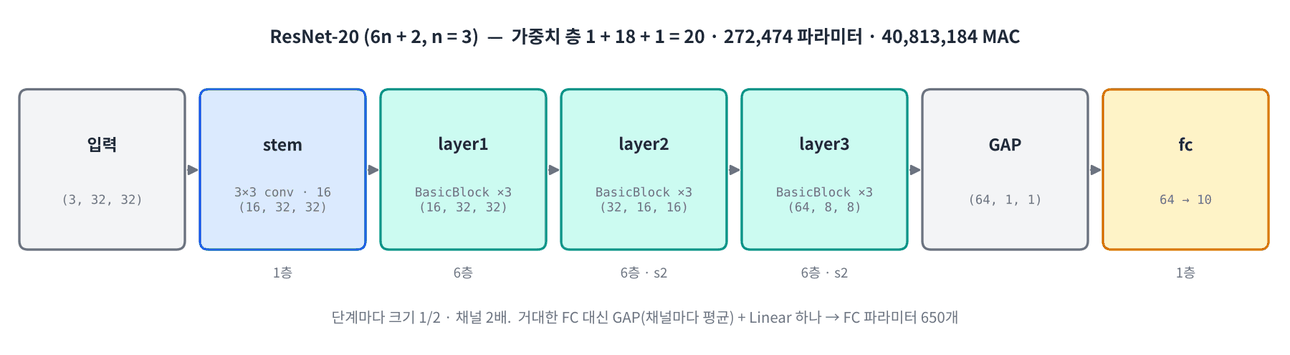

In [ ]:
#@title 🖼 그림 — ResNet-20 구조 — 단계마다 크기 1/2, 채널 2배
from IPython.display import Image, display
display(Image(url="https://raw.githubusercontent.com/imguru-mooc/AI_CAMPUS/main/VB-day2/img/f6_resnet20.png", embed=True, width=860))

**문제 6-2** `ResNet` 클래스를 완성하세요. `make_layer` 는 첫 블록만 `stride` 를 쓰고 나머지는 stride 1 입니다.

In [ ]:
class ResNet(nn.Module):
    def __init__(self, n=3, n_cls=10, residual=True):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        self.layer1 = self.make_layer(16, 16, n, stride=1, residual=residual)
        self.layer2 = self.make_layer(16, 32, n, stride=____, residual=residual)
        self.layer3 = self.make_layer(32, ____, n, stride=2, residual=residual)
        self.pool = nn.AdaptiveAvgPool2d(1)          # GAP: (N, 64, 8, 8) → (N, 64, 1, 1)
        self.fc = nn.Linear(64, n_cls)

    @staticmethod
    def make_layer(cin, cout, n, stride, residual):
        blocks = [BasicBlock(cin, cout, stride, residual)]
        for _ in range(n - 1):
            blocks.append(BasicBlock(____, cout, 1, residual))
        return nn.Sequential(*blocks)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer3(self.layer2(self.layer1(x)))
        return self.fc(self.pool(x).____)

def resnet20(residual=True):
    return ResNet(n=3, residual=residual)

net = resnet20()
print("ResNet-20 파라미터:", f"{count_params(net):,}", "| 출력:", tuple(net(torch.zeros(2, 3, 32, 32)).shape))

In [ ]:
assert count_params(net) == 272_474 and net(torch.zeros(2, 3, 32, 32)).shape == (2, 10); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTIg4pSA4pSACmNsYXNzIFJlc05ldChubi5Nb2R1bGUpOgogICAgZGVmIF9faW5pdF9f"
    "KHNlbGYsIG49Mywgbl9jbHM9MTAsIHJlc2lkdWFsPVRydWUpOgogICAgICAgIHN1cGVyKCkuX19pbml0X18oKQog"
    "ICAgICAgIHNlbGYuc3RlbSA9IG5uLlNlcXVlbnRpYWwobm4uQ29udjJkKDMsIDE2LCAzLCBwYWRkaW5nPTEsIGJp"
    "YXM9RmFsc2UpLCBubi5CYXRjaE5vcm0yZCgxNiksIG5uLlJlTFUoaW5wbGFjZT1UcnVlKSkKICAgICAgICBzZWxm"
    "LmxheWVyMSA9IHNlbGYubWFrZV9sYXllcigxNiwgMTYsIG4sIHN0cmlkZT0xLCByZXNpZHVhbD1yZXNpZHVhbCkK"
    "ICAgICAgICBzZWxmLmxheWVyMiA9IHNlbGYubWFrZV9sYXllcigxNiwgMzIsIG4sIHN0cmlkZT0yLCByZXNpZHVh"
    "bD1yZXNpZHVhbCkKICAgICAgICBzZWxmLmxheWVyMyA9IHNlbGYubWFrZV9sYXllcigzMiwgNjQsIG4sIHN0cmlk"
    "ZT0yLCByZXNpZHVhbD1yZXNpZHVhbCkKICAgICAgICBzZWxmLnBvb2wgPSBubi5BZGFwdGl2ZUF2Z1Bvb2wyZCgx"
    "KSAgICAgICAgICAjIEdBUDogKE4sIDY0LCA4LCA4KSDihpIgKE4sIDY0LCAxLCAxKQogICAgICAgIHNlbGYuZmMg"
    "PSBubi5MaW5lYXIoNjQsIG5fY2xzKQoKICAgIEBzdGF0aWNtZXRob2QKICAgIGRlZiBtYWtlX2xheWVyKGNpbiwg"
    "Y291dCwgbiwgc3RyaWRlLCByZXNpZHVhbCk6CiAgICAgICAgYmxvY2tzID0gW0Jhc2ljQmxvY2soY2luLCBjb3V0"
    "LCBzdHJpZGUsIHJlc2lkdWFsKV0KICAgICAgICBmb3IgXyBpbiByYW5nZShuIC0gMSk6CiAgICAgICAgICAgIGJs"
    "b2Nrcy5hcHBlbmQoQmFzaWNCbG9jayhjb3V0LCBjb3V0LCAxLCByZXNpZHVhbCkpCiAgICAgICAgcmV0dXJuIG5u"
    "LlNlcXVlbnRpYWwoKmJsb2NrcykKCiAgICBkZWYgZm9yd2FyZChzZWxmLCB4KToKICAgICAgICB4ID0gc2VsZi5z"
    "dGVtKHgpCiAgICAgICAgeCA9IHNlbGYubGF5ZXIzKHNlbGYubGF5ZXIyKHNlbGYubGF5ZXIxKHgpKSkKICAgICAg"
    "ICByZXR1cm4gc2VsZi5mYyhzZWxmLnBvb2woeCkuZmxhdHRlbigxKSkKCmRlZiByZXNuZXQyMChyZXNpZHVhbD1U"
    "cnVlKToKICAgIHJldHVybiBSZXNOZXQobj0zLCByZXNpZHVhbD1yZXNpZHVhbCkKCm5ldCA9IHJlc25ldDIwKCkK"
    "cHJpbnQoIlJlc05ldC0yMCDtjIzrnbzrr7jthLA6IiwgZiJ7Y291bnRfcGFyYW1zKG5ldCk6LH0iLCAifCDstpzr"
    "oKU6IiwgdHVwbGUobmV0KHRvcmNoLnplcm9zKDIsIDMsIDMyLCAzMikpLnNoYXBlKSkKCvCfkqEg7ZW07ISkClJl"
    "c05ldC0yMCDsnYAgMjcyLDQ3NCDtjIzrnbzrr7jthLAg4oCUIFZHRy1taW5pKDMwNyw5NDYpIOuztOuLpCDsoIHq"
    "s6AgTUxQIOydmCAxLzYg7J6F64uI64ukLiDqsbDrjIDtlZwgRkMg64yA7IugIEdBUCjssYTrhJDrp4jri6Qg7Y+J"
    "6regIO2VmOuCmCkgKyBMaW5lYXIoNjQg4oaSIDEwKSDrpbwg7I2o7IScIEZDIO2MjOudvOuvuO2EsOqwgCA2NTDq"
    "sJzrv5DsnoXri4jri6Qu"
).decode("utf-8"))

**문제 6-3** 같은 구조에서 **지름길만 뺀** plain-20 과 ResNet-20 을 5교시와 같은 조건(10,000장, SGD 0.05, 3 epoch) 으로 비교하세요. 학습 전 첫 합성곱 층의 기울기 크기와, 학습 후 train 손실 · test 정확도를 함께 봅니다.

In [ ]:
cmp_hist, first_grad = {}, {}
for res in (False, True):
    torch.manual_seed(0)
    net = resnet20(residual=____).to(device)
    xb_, yb_ = xb.to(device), yb.to(device)
    net.zero_grad(); F.cross_entropy(net(xb_), yb_).backward()
    first_grad[res] = net.stem[0].weight.grad.norm().item()
    opt = torch.optim.SGD(net.parameters(), lr=0.05, momentum=0.9)
    cmp_hist[res] = fit(net, small_loader, test_loader, 3, opt, label="ResNet-20" if res else "plain-20 ")

In [ ]:
for res, name in ((False, "plain-20 "), (True, "ResNet-20")):
    print(f"{name}  첫 층 기울기 {first_grad[res]:.3e}  train loss {cmp_hist[res]['loss'][-1]:.4f}  test {cmp_hist[res]['test_acc'][-1]:.4f}")
assert len(cmp_hist) == 2 and all(len(h["loss"]) == 3 for h in cmp_hist.values()); print("✅")

In [ ]:
#@title 🔒 정답 보기 6-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA2LTMg4pSA4pSACmNtcF9oaXN0LCBmaXJzdF9ncmFkID0ge30sIHt9CmZvciByZXMgaW4g"
    "KEZhbHNlLCBUcnVlKToKICAgIHRvcmNoLm1hbnVhbF9zZWVkKDApCiAgICBuZXQgPSByZXNuZXQyMChyZXNpZHVh"
    "bD1yZXMpLnRvKGRldmljZSkKICAgIHhiXywgeWJfID0geGIudG8oZGV2aWNlKSwgeWIudG8oZGV2aWNlKQogICAg"
    "bmV0Lnplcm9fZ3JhZCgpOyBGLmNyb3NzX2VudHJvcHkobmV0KHhiXyksIHliXykuYmFja3dhcmQoKQogICAgZmly"
    "c3RfZ3JhZFtyZXNdID0gbmV0LnN0ZW1bMF0ud2VpZ2h0LmdyYWQubm9ybSgpLml0ZW0oKQogICAgb3B0ID0gdG9y"
    "Y2gub3B0aW0uU0dEKG5ldC5wYXJhbWV0ZXJzKCksIGxyPTAuMDUsIG1vbWVudHVtPTAuOSkKICAgIGNtcF9oaXN0"
    "W3Jlc10gPSBmaXQobmV0LCBzbWFsbF9sb2FkZXIsIHRlc3RfbG9hZGVyLCAzLCBvcHQsIGxhYmVsPSJSZXNOZXQt"
    "MjAiIGlmIHJlcyBlbHNlICJwbGFpbi0yMCAiKQoK8J+SoSDtlbTshKQK7Iuk7ZaJIOyYiDog7ZWZ7Iq1IOyghCDs"
    "sqsg7Li1IOq4sOyauOq4sOuKlCBwbGFpbi0yMCA5Ljg0ZS0wMSDCtyBSZXNOZXQtMjAgOC4zMmUtMDEg66GcIOu5"
    "hOyKt+2VqeuLiOuLpCDigJQg65GYIOuLpCBCTiDsnbQg7J6I7Ja07IScIO2VmeyKtSDsi5zsnpHsnYAg66y47KCc"
    "7JeG7Iq164uI64ukLiDssKjsnbTripQg7ZWZ7Iq17ZWY66m07IScIOuCmO2DgOuCqeuLiOuLpDogMyBlcG9jaCDr"
    "kqQgdHJhaW4g7IaQ7IukIDEuNjQxIHZzIDEuNDM4LCB0ZXN0IDAuMzgwIHZzIDAuNDQzLiDtjIzrnbzrr7jthLAg"
    "7IiY6rCAIOqwmeydgOuNsCjsp4DrpoTquLjsnYAg6rCZ7J2AIDHDlzEgQ29udiDrpbwg7JOw7KeA66eMIHBsYWlu"
    "IOyXkOyEnOuKlCBmb3J3YXJkIOyXkCDsk7DsnbTsp4Ag7JWK7J2EIOu/kCkg7KeA66aE6ri47J20IOyeiOuKlCDs"
    "qr3snbQg642UIOu5qOumrCwg642UIOuCruydgCDshpDsi6TroZwg67Cw7JuB64uI64ukIOKAlCDshLHriqUg7KCA"
    "7ZWY6rCAIOyCrOudvOynhCDqsoPsnoXri4jri6Qu"
).decode("utf-8"))

#### 📌 6교시 정리

- 깊은 plain 망은 BN 이 있어도 성능 저하(degradation) — 항등 함수를 배우기 어렵다.
- Residual: `y = ReLU(F(x) + x)`. 덧셈 노드 덕분에 기울기에 항상 +1 이 남는다.
- 모양이 바뀌는 블록은 1×1 Conv(stride) + BN 지름길. ResNet-20 = 6·3 + 2 층, GAP + FC 하나.

## 7교시 — 학습 기법: 데이터 증강 · 학습률 스케줄 · 혼동 행렬 · 연산량

8교시에 ResNet-20 으로 85% 를 넘으려면 구조만으로는 부족합니다. 같은 모델도 **어떻게 학습시키느냐**로 몇 %p 가 갈립니다.

> 🎬 **애니메이션** [D2-7 데이터 증강 · 학습률 스케줄](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-7)
> 📝 **워크시트** [7교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t7)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 데이터 증강 (data augmentation)

학습할 때마다 이미지를 **조금씩 다르게** 보여 줍니다. 모델은 같은 사진을 두 번 보지 않으므로 외우기 어렵고, 위치 · 좌우가 바뀌어도 같은 물체라는 것을 배웁니다. 정답이 바뀌지 않는 변형만 씁니다 (숫자 6 을 뒤집으면 9 가 되는 MNIST 에는 좌우 뒤집기를 쓰면 안 됩니다).

| 변형 | 코드 | 효과 |
|---|---|---|
| 랜덤 자르기 | `RandomCrop(32, padding=4)` | 사방에 4픽셀 0 을 덧대고 32×32 를 무작위 위치에서 자름 → 최대 ±4 픽셀 이동 |
| 좌우 뒤집기 | `RandomHorizontalFlip()` | 50% 확률로 좌우 반전 |

증강은 **train 에만** 씁니다. test 는 언제나 원본 그대로 평가합니다.

**문제 7-1** 증강 transform 을 완성하세요. 증강(PIL 이미지에 적용) → ToTensor → Normalize 순서입니다. 아래 셀이 같은 사진 한 장을 8번 꺼내 보여 줍니다.

In [ ]:
train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=____),
    transforms.____,
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
aug_set = datasets.CIFAR10("data", train=True, download=False, transform=train_tf)

In [ ]:
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, ax = plt.subplots(1, 9, figsize=(13, 1.8))
ax[0].imshow(train_set.data[7]); ax[0].set_title("original")
for k in range(1, 9):
    ax[k].imshow((aug_set[7][0] * std_t + mean_t).permute(1, 2, 0).clamp(0, 1)); ax[k].set_title(f"aug {k}")
for a in ax: a.axis("off")
plt.show()
assert aug_set[7][0].shape == (3, 32, 32) and isinstance(train_tf.transforms[1], transforms.RandomHorizontalFlip); print("✅")

In [ ]:
#@title 🔒 정답 보기 7-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTEg4pSA4pSACnRyYWluX3RmID0gdHJhbnNmb3Jtcy5Db21wb3NlKFsKICAgIHRyYW5z"
    "Zm9ybXMuUmFuZG9tQ3JvcCgzMiwgcGFkZGluZz00KSwKICAgIHRyYW5zZm9ybXMuUmFuZG9tSG9yaXpvbnRhbEZs"
    "aXAoKSwKICAgIHRyYW5zZm9ybXMuVG9UZW5zb3IoKSwKICAgIHRyYW5zZm9ybXMuTm9ybWFsaXplKE1FQU4sIFNU"
    "RCksCl0pCmF1Z19zZXQgPSBkYXRhc2V0cy5DSUZBUjEwKCJkYXRhIiwgdHJhaW49VHJ1ZSwgZG93bmxvYWQ9RmFs"
    "c2UsIHRyYW5zZm9ybT10cmFpbl90ZikKCvCfkqEg7ZW07ISkCmF1Z19zZXRbN10g66W8IOq6vOuCvCDrlYzrp4jr"
    "i6Qg7IOI66GcIOyekOultOqzoCDrkqTsp5HsnLzrr4DroZwg66ek67KIIOuLpOuluCDqt7jrprzsnbQg64KY7Ji1"
    "64uI64ukLiDtmZTrqbTsl5Ag6re466a0IOuVjOuKlCBOb3JtYWxpemUg66W8IOuQmOuPjOugpOyVvCjDlyBzdGQg"
    "KyBtZWFuKSDsm5Drnpgg7IOJ7Jy866GcIOuztOyeheuLiOuLpC4="
).decode("utf-8"))

### 학습률 스케줄 — OneCycle

처음부터 큰 학습률이면 불안정하고, 끝까지 크면 최솟값 근처에서 출렁입니다. **OneCycleLR** 은 학습률을 작게 시작해 최댓값까지 올렸다가(warm-up) 끝으로 갈수록 거의 0 까지 내립니다. 짧은 학습에서 특히 효과적이라 8교시에 씁니다. 배치마다 `scheduler.step()` 을 부릅니다 (환경 셀의 `train_one_epoch` 에 이미 들어 있음).

**문제 7-2** 15 epoch · epoch 당 391 step(50,000 / 128 올림) 동안 OneCycleLR 의 학습률 변화를 그려 보세요. 실제 학습 없이 옵티마이저만 만들어 `step()` 을 반복합니다.

In [ ]:
dummy = torch.nn.Parameter(torch.zeros(1))
opt_d = torch.optim.SGD([dummy], lr=0.1, momentum=0.9)
sched = torch.optim.lr_scheduler.OneCycleLR(opt_d, max_lr=____, epochs=15, steps_per_epoch=____)
lrs = []
for _ in range(15 * 391):
    opt_d.step()
    sched.step()
    lrs.append(sched.get_last_lr()[0])
plt.figure(figsize=(6, 3)); plt.plot(lrs); plt.xlabel("step"); plt.ylabel("learning rate"); plt.grid(alpha=.3); plt.title("OneCycleLR (max 0.1, 15 epochs)"); plt.show()
peak = int(np.argmax(lrs))
print(f"시작 {lrs[0]:.4f} → 최대 {max(lrs):.4f} (step {peak}, {peak / len(lrs):.0%} 지점) → 끝 {lrs[-1]:.2e}")

In [ ]:
assert abs(max(lrs) - 0.1) < 1e-6 and lrs[0] < 0.01 and lrs[-1] < 1e-4 and 0.25 < peak / len(lrs) < 0.35; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTIg4pSA4pSACmR1bW15ID0gdG9yY2gubm4uUGFyYW1ldGVyKHRvcmNoLnplcm9zKDEp"
    "KQpvcHRfZCA9IHRvcmNoLm9wdGltLlNHRChbZHVtbXldLCBscj0wLjEsIG1vbWVudHVtPTAuOSkKc2NoZWQgPSB0"
    "b3JjaC5vcHRpbS5scl9zY2hlZHVsZXIuT25lQ3ljbGVMUihvcHRfZCwgbWF4X2xyPTAuMSwgZXBvY2hzPTE1LCBz"
    "dGVwc19wZXJfZXBvY2g9MzkxKQpscnMgPSBbXQpmb3IgXyBpbiByYW5nZSgxNSAqIDM5MSk6CiAgICBvcHRfZC5z"
    "dGVwKCkKICAgIHNjaGVkLnN0ZXAoKQogICAgbHJzLmFwcGVuZChzY2hlZC5nZXRfbGFzdF9scigpWzBdKQpwbHQu"
    "ZmlndXJlKGZpZ3NpemU9KDYsIDMpKTsgcGx0LnBsb3QobHJzKTsgcGx0LnhsYWJlbCgic3RlcCIpOyBwbHQueWxh"
    "YmVsKCJsZWFybmluZyByYXRlIik7IHBsdC5ncmlkKGFscGhhPS4zKTsgcGx0LnRpdGxlKCJPbmVDeWNsZUxSICht"
    "YXggMC4xLCAxNSBlcG9jaHMpIik7IHBsdC5zaG93KCkKcGVhayA9IGludChucC5hcmdtYXgobHJzKSkKcHJpbnQo"
    "ZiLsi5zsnpEge2xyc1swXTouNGZ9IOKGkiDstZzrjIAge21heChscnMpOi40Zn0gKHN0ZXAge3BlYWt9LCB7cGVh"
    "ayAvIGxlbihscnMpOi4wJX0g7KeA7KCQKSDihpIg64GdIHtscnNbLTFdOi4yZX0iKQoK8J+SoSDtlbTshKQK6riw"
    "67O46rCS7Jy866GcIOyghOyytOydmCAzMCUg7KeA7KCQ7JeQ7IScIOy1nOuMgCgwLjEp7JeQIOuLv+qzoCwg7Iuc"
    "7J6R7J2AIG1heF9sciAvIDI1ID0gMC4wMDQsIOuBneydgCDqt7jrs7Tri6QgMTDigbQg67CwIOyekeydgCDqsJLq"
    "uYzsp4Ag64K066Ck6rCR64uI64ukLiBzdGVwc19wZXJfZXBvY2gg64qUIGxlbih0cmFpbl9sb2FkZXIpIOyZgCDq"
    "sJnslYTslbwg7ZWp64uI64ukIOKAlCDti4DrpqzrqbQg7ZWZ7Iq1IOuBneyXkCAnVHJpZWQgdG8gc3RlcCAuLi4g"
    "dGltZXMnIOyYpOulmOqwgCDrgqnri4jri6Qu"
).decode("utf-8"))

### 혼동 행렬 (confusion matrix) — 무엇을 무엇으로 틀리나

정확도 하나로는 **어떤 클래스끼리 헷갈리는지** 알 수 없습니다. 혼동 행렬 `M[i, j]` = 정답이 i 인데 j 로 예측한 개수. 대각선이 맞힌 것, 나머지가 틀린 것입니다.

**문제 7-3** 예측 · 정답 배열로 혼동 행렬을 만드는 함수를 완성하고, 4교시 VGG-mini 의 test 혼동 행렬을 그리세요. 힌트: `정답 × K + 예측` 을 세면 K×K 칸 각각의 개수가 됩니다.

In [ ]:
def predict_all(model, loader):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for xb_, yb_ in loader:
            P.append(model(xb_.to(device)).argmax(1).cpu()); Y.append(yb_)
    return torch.cat(P).numpy(), torch.cat(Y).numpy()

def confusion_matrix(pred, true, K=10):
    return np.bincount(____, minlength=K * K).reshape(____)

pred_vgg, true_vgg = predict_all(vgg, test_loader)
cm = confusion_matrix(pred_vgg, true_vgg)

In [ ]:
assert cm.sum() == 10_000 and np.trace(cm) / cm.sum() == hist_vgg["test_acc"][-1]; print("✅ 대각합 / 전체 =", np.trace(cm) / cm.sum())
plt.figure(figsize=(6, 5)); plt.imshow(cm, cmap="Blues"); plt.colorbar()
plt.xticks(range(10), CLASSES, rotation=60); plt.yticks(range(10), CLASSES); plt.xlabel("predicted"); plt.ylabel("true")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=7, color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.title("VGG-mini confusion matrix"); plt.show()
off = cm.copy(); np.fill_diagonal(off, 0)
i, j = np.unravel_index(off.argmax(), off.shape)
print(f"가장 많이 헷갈린 쌍: {CLASSES[i]} → {CLASSES[j]} ({off[i, j]}장)")

In [ ]:
#@title 🔒 정답 보기 7-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTMg4pSA4pSACmRlZiBwcmVkaWN0X2FsbChtb2RlbCwgbG9hZGVyKToKICAgIG1vZGVs"
    "LmV2YWwoKTsgUCwgWSA9IFtdLCBbXQogICAgd2l0aCB0b3JjaC5ub19ncmFkKCk6CiAgICAgICAgZm9yIHhiXywg"
    "eWJfIGluIGxvYWRlcjoKICAgICAgICAgICAgUC5hcHBlbmQobW9kZWwoeGJfLnRvKGRldmljZSkpLmFyZ21heCgx"
    "KS5jcHUoKSk7IFkuYXBwZW5kKHliXykKICAgIHJldHVybiB0b3JjaC5jYXQoUCkubnVtcHkoKSwgdG9yY2guY2F0"
    "KFkpLm51bXB5KCkKCmRlZiBjb25mdXNpb25fbWF0cml4KHByZWQsIHRydWUsIEs9MTApOgogICAgcmV0dXJuIG5w"
    "LmJpbmNvdW50KHRydWUgKiBLICsgcHJlZCwgbWlubGVuZ3RoPUsgKiBLKS5yZXNoYXBlKEssIEspCgpwcmVkX3Zn"
    "ZywgdHJ1ZV92Z2cgPSBwcmVkaWN0X2FsbCh2Z2csIHRlc3RfbG9hZGVyKQpjbSA9IGNvbmZ1c2lvbl9tYXRyaXgo"
    "cHJlZF92Z2csIHRydWVfdmdnKQoK8J+SoSDtlbTshKQK64yA6rCB7ISg7J2YIO2VqSAvIOyghOyytCA9IOygle2Z"
    "leuPhC4g7Iuk7ZaJIOyYiOyXkOyEnCDqsIDsnqUg66eO7J20IO2Xt+qwiOumsCDsjI3snYAgY2F0IOKGkiBkb2cg"
    "KDE4MOyepSkg7JiA7Iq164uI64ukIOKAlCDrj5nrrLzrgbzrpqwsIO2Kue2eiCBjYXQg4oaUIGRvZyDqsIAg64qY"
    "IOyDgeychOq2jOyeheuLiOuLpC4="
).decode("utf-8"))

### 연산량 — 파라미터만으로는 속도를 알 수 없다

온디바이스에서 중요한 것은 **곱셈-덧셈 수 (MAC)** 입니다. NN Day 5 공식: Conv MAC = Cout · OH · OW · (Cin / G) · K², Linear MAC = in · out. PyTorch 의 **forward hook** (계층이 실행될 때마다 불리는 함수) 으로 실제 출력 크기를 잡아 계산합니다.

**문제 7-4** hook 으로 이미지 한 장의 MAC 을 세는 함수를 완성하고, 오늘 만든 네 모델을 비교하세요.

In [ ]:
def count_macs(model, input_size=(1, 3, 32, 32)):
    total = [0]
    def hook(m, inp, out):
        if isinstance(m, nn.Conv2d):
            cout, oh, ow = out.shape[1:]
            total[0] += cout * oh * ow * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
        elif isinstance(m, nn.Linear):
            total[0] += m.in_features * ____
    hs = [m.register_forward_hook(hook) for m in model.modules() if isinstance(m, (nn.Conv2d, nn.Linear))]
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=next(model.parameters()).device))
    for h in hs:
        h.____
    return total[0]

table = {}
for name, m in [("MLP", mlp), ("LeNet-5", lenet), ("VGG-mini", vgg), ("ResNet-20", resnet20().to(device))]:
    table[name] = (count_params(m), count_macs(m))
    print(f"{name:10s} 파라미터 {table[name][0]:>10,}   MAC {table[name][1]:>12,}")

In [ ]:
assert table["LeNet-5"][1] == 651_720 and table["MLP"][1] == 1_706_496; print("✅")

In [ ]:
#@title 🔒 정답 보기 7-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA3LTQg4pSA4pSACmRlZiBjb3VudF9tYWNzKG1vZGVsLCBpbnB1dF9zaXplPSgxLCAzLCAz"
    "MiwgMzIpKToKICAgIHRvdGFsID0gWzBdCiAgICBkZWYgaG9vayhtLCBpbnAsIG91dCk6CiAgICAgICAgaWYgaXNp"
    "bnN0YW5jZShtLCBubi5Db252MmQpOgogICAgICAgICAgICBjb3V0LCBvaCwgb3cgPSBvdXQuc2hhcGVbMTpdCiAg"
    "ICAgICAgICAgIHRvdGFsWzBdICs9IGNvdXQgKiBvaCAqIG93ICogKG0uaW5fY2hhbm5lbHMgLy8gbS5ncm91cHMp"
    "ICogbS5rZXJuZWxfc2l6ZVswXSAqIG0ua2VybmVsX3NpemVbMV0KICAgICAgICBlbGlmIGlzaW5zdGFuY2UobSwg"
    "bm4uTGluZWFyKToKICAgICAgICAgICAgdG90YWxbMF0gKz0gbS5pbl9mZWF0dXJlcyAqIG0ub3V0X2ZlYXR1cmVz"
    "CiAgICBocyA9IFttLnJlZ2lzdGVyX2ZvcndhcmRfaG9vayhob29rKSBmb3IgbSBpbiBtb2RlbC5tb2R1bGVzKCkg"
    "aWYgaXNpbnN0YW5jZShtLCAobm4uQ29udjJkLCBubi5MaW5lYXIpKV0KICAgIG1vZGVsLmV2YWwoKQogICAgd2l0"
    "aCB0b3JjaC5ub19ncmFkKCk6CiAgICAgICAgbW9kZWwodG9yY2guemVyb3MoaW5wdXRfc2l6ZSwgZGV2aWNlPW5l"
    "eHQobW9kZWwucGFyYW1ldGVycygpKS5kZXZpY2UpKQogICAgZm9yIGggaW4gaHM6CiAgICAgICAgaC5yZW1vdmUo"
    "KQogICAgcmV0dXJuIHRvdGFsWzBdCgp0YWJsZSA9IHt9CmZvciBuYW1lLCBtIGluIFsoIk1MUCIsIG1scCksICgi"
    "TGVOZXQtNSIsIGxlbmV0KSwgKCJWR0ctbWluaSIsIHZnZyksICgiUmVzTmV0LTIwIiwgcmVzbmV0MjAoKS50byhk"
    "ZXZpY2UpKV06CiAgICB0YWJsZVtuYW1lXSA9IChjb3VudF9wYXJhbXMobSksIGNvdW50X21hY3MobSkpCiAgICBw"
    "cmludChmIntuYW1lOjEwc30g7YyM652866+47YSwIHt0YWJsZVtuYW1lXVswXTo+MTAsfSAgIE1BQyB7dGFibGVb"
    "bmFtZV1bMV06PjEyLH0iKQoK8J+SoSDtlbTshKQKTGVOZXQtNTogY29udjEgNsK3MjjCtzI4wrczwrcyNSA9IDM1"
    "Miw4MDAgKyBjb252MiAxNsK3MTDCtzEwwrc2wrcyNSA9IDI0MCwwMDAgKyBGQyA1OCw5MjAgPSA2NTEsNzIwLiBo"
    "b29rIOydgCDri6Qg7JOw66m0IHJlbW92ZSgpIOuhnCDrlrzslrQg64K07JW8IOuLpOydjCDsi6Ttlonsl5Ag7KSR"
    "67O17Jy866GcIOu2meyngCDslYrsirXri4jri6QuClJlc05ldC0yMCDsnYAg7YyM652866+47YSwIDI3Miw0NzQg"
    "6rCc66GcIE1MUCDsnZggMS82IOydtOyngOunjCBNQUMg7J2AIDQwLDgxMywxODQg4oCUIE1MUCgxLDcwNiw0OTYp"
    "IOydmCDslb0gMjTrsLDsnoXri4jri6QuIO2VqeyEseqzseydgCDqsJnsnYAg6rCA7KSR7LmY66W8IOuqqOuToCDs"
    "nITsuZjsl5DshJwg64uk7IucIOyTsOq4sCDrlYzrrLjsnoXri4jri6QuIFF1YW50aXphdGlvbiDqs7zrqqnsl5Ds"
    "hJwg7J20IOuRkCDsiKvsnpDrpbwg7ZWo6ruYIOykhOyeheuLiOuLpC4="
).decode("utf-8"))

#### 📌 7교시 정리

- 데이터 증강 (RandomCrop 4 · Flip) 은 train 에만 — 외우기를 막고 위치 · 좌우 변화에 강해진다.
- OneCycleLR: 0.004 → 0.1 (30% 지점) → 거의 0, 배치마다 `step()`.
- 혼동 행렬로 '무엇을 무엇으로' 틀리는지 본다. 파라미터와 MAC 은 따로 본다.

## 8교시 — 미니 프로젝트: CIFAR-10 ResNet-20 85% 도전

오늘 만든 모든 것을 합칩니다: **ResNet-20 + 데이터 증강 + SGD(momentum · weight decay) + OneCycleLR**.

| 과제 | 내용 | 배점 |
|---|---|---|
| 1 | 증강 train 로더 · 학습 설정 (SGD · OneCycle) | 20 |
| 2 | ResNet-20 20 epoch 학습 — **test ≥ 0.85** | 35 |
| 3 | 오답 분석 — 혼동 행렬 · 가장 헷갈린 쌍 3개 · 오답 그림 | 15 |
| 4 | 모델 비교표 (파라미터 · MAC · test 정확도) | 10 |
| 5 | 결과 해석 (마크다운 답변) | 10 + 10 (강사) |

학습 시간: **T4 GPU 로 epoch 당 약 20초, 20 epoch 약 7분 (예상)**. 강사 사전 실행 예: 20 epoch test **0.8587** (15 epoch 로는 0.8479 로 목표에 조금 못 미쳐 20 epoch 으로 정했습니다). GPU 를 못 받은 경우(CPU) 에는 과제 2 셀이 강사가 미리 학습한 가중치를 내려받아 이어서 진행합니다 (과제 2 점수는 GPU 로 직접 학습한 경우에만).

과제 끝의 **채점 셀**을 실행하면 자동 채점 점수가 나옵니다. 제출은 채점 셀 결과가 보이는 상태로 이 노트북을 공유합니다.

> 🎬 **애니메이션** [D2-8 ResNet-20 학습 · 오답 분석](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/animation.html#d2-8)
> 📝 **워크시트** [8교시 개념 워크시트 (10문항)](https://imguru-mooc.github.io/AI_CAMPUS/VB-day2/worksheet.html#t8)
> 수업 전에 애니메이션으로 **예측**하고, 노트북 코드로 **확인**한 뒤, 워크시트로 **점검**합니다.

### 과제 1 — 증강 로더 · 학습 설정 (20점)

- train 로더: 7교시 `aug_set` (증강), 배치 128, 섞기
- 옵티마이저: SGD lr 0.1, momentum 0.9, **nesterov=True**, weight_decay **5e-4** (NN Day 4 의 L2 규제)
- 스케줄러: OneCycleLR max_lr 0.1, `EPOCHS` 20, steps_per_epoch = 로더 길이 (7교시 그림은 15 epoch 예시였습니다)

In [ ]:
EPOCHS = 20
aug_loader = DataLoader(aug_set, batch_size=128, shuffle=True, num_workers=NW, pin_memory=True, drop_last=False)

torch.manual_seed(0)
model = resnet20().to(device)
opt = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, nesterov=____, weight_decay=____)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=0.1, epochs=EPOCHS, steps_per_epoch=____)
print("step / epoch:", len(aug_loader), "| 파라미터:", f"{count_params(model):,}")

In [ ]:
#@title 🔒 정답 보기 8-1 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTEg4pSA4pSACkVQT0NIUyA9IDIwCmF1Z19sb2FkZXIgPSBEYXRhTG9hZGVyKGF1Z19z"
    "ZXQsIGJhdGNoX3NpemU9MTI4LCBzaHVmZmxlPVRydWUsIG51bV93b3JrZXJzPU5XLCBwaW5fbWVtb3J5PVRydWUs"
    "IGRyb3BfbGFzdD1GYWxzZSkKCnRvcmNoLm1hbnVhbF9zZWVkKDApCm1vZGVsID0gcmVzbmV0MjAoKS50byhkZXZp"
    "Y2UpCm9wdCA9IHRvcmNoLm9wdGltLlNHRChtb2RlbC5wYXJhbWV0ZXJzKCksIGxyPTAuMSwgbW9tZW50dW09MC45"
    "LCBuZXN0ZXJvdj1UcnVlLCB3ZWlnaHRfZGVjYXk9NWUtNCkKc2NoZWQgPSB0b3JjaC5vcHRpbS5scl9zY2hlZHVs"
    "ZXIuT25lQ3ljbGVMUihvcHQsIG1heF9scj0wLjEsIGVwb2Nocz1FUE9DSFMsIHN0ZXBzX3Blcl9lcG9jaD1sZW4o"
    "YXVnX2xvYWRlcikpCnByaW50KCJzdGVwIC8gZXBvY2g6IiwgbGVuKGF1Z19sb2FkZXIpLCAifCDtjIzrnbzrr7jt"
    "hLA6IiwgZiJ7Y291bnRfcGFyYW1zKG1vZGVsKTosfSIp"
).decode("utf-8"))

### 과제 2 — 학습 (35점)

`fit` 에 스케줄러를 넘깁니다. GPU 가 없으면 학습 대신 강사가 학습한 가중치를 내려받습니다.

In [ ]:
TRAINED_ON_GPU = device.type == "cuda"
if TRAINED_ON_GPU:
    t_start = time.perf_counter()
    hist_res = fit(model, ____, test_loader, EPOCHS, opt, ____, label="ResNet-20")
    train_min = (time.perf_counter() - t_start) / 60
    print(f"학습 시간 {train_min:.1f} 분")
else:
    print("GPU 없음 → 강사가 학습한 가중치를 내려받습니다 (과제 2 점수 제외)")
    urllib.request.urlretrieve(f"{RAW}/data/resnet20_cifar10.pt", "resnet20_cifar10_ref.pt")
    model.load_state_dict(torch.load("resnet20_cifar10_ref.pt", map_location=device))
    hist_res = {"loss": [], "train_acc": [], "test_acc": [evaluate(model, test_loader)]}
res_acc = hist_res["test_acc"][-1]
torch.save(model.state_dict(), "resnet20_cifar10.pt")
print("test 정확도:", res_acc)

In [ ]:
#@title 🔒 정답 보기 8-2 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTIg4pSA4pSAClRSQUlORURfT05fR1BVID0gZGV2aWNlLnR5cGUgPT0gImN1ZGEiCmlm"
    "IFRSQUlORURfT05fR1BVOgogICAgdF9zdGFydCA9IHRpbWUucGVyZl9jb3VudGVyKCkKICAgIGhpc3RfcmVzID0g"
    "Zml0KG1vZGVsLCBhdWdfbG9hZGVyLCB0ZXN0X2xvYWRlciwgRVBPQ0hTLCBvcHQsIHNjaGVkLCBsYWJlbD0iUmVz"
    "TmV0LTIwIikKICAgIHRyYWluX21pbiA9ICh0aW1lLnBlcmZfY291bnRlcigpIC0gdF9zdGFydCkgLyA2MAogICAg"
    "cHJpbnQoZiLtlZnsirUg7Iuc6rCEIHt0cmFpbl9taW46LjFmfSDrtoQiKQplbHNlOgogICAgcHJpbnQoIkdQVSDs"
    "l4bsnYwg4oaSIOqwleyCrOqwgCDtlZnsirXtlZwg6rCA7KSR7LmY66W8IOuCtOugpOuwm+yKteuLiOuLpCAo6rO8"
    "7KCcIDIg7KCQ7IiYIOygnOyZuCkiKQogICAgdXJsbGliLnJlcXVlc3QudXJscmV0cmlldmUoZiJ7UkFXfS9kYXRh"
    "L3Jlc25ldDIwX2NpZmFyMTAucHQiLCAicmVzbmV0MjBfY2lmYXIxMF9yZWYucHQiKQogICAgbW9kZWwubG9hZF9z"
    "dGF0ZV9kaWN0KHRvcmNoLmxvYWQoInJlc25ldDIwX2NpZmFyMTBfcmVmLnB0IiwgbWFwX2xvY2F0aW9uPWRldmlj"
    "ZSkpCiAgICBoaXN0X3JlcyA9IHsibG9zcyI6IFtdLCAidHJhaW5fYWNjIjogW10sICJ0ZXN0X2FjYyI6IFtldmFs"
    "dWF0ZShtb2RlbCwgdGVzdF9sb2FkZXIpXX0KcmVzX2FjYyA9IGhpc3RfcmVzWyJ0ZXN0X2FjYyJdWy0xXQp0b3Jj"
    "aC5zYXZlKG1vZGVsLnN0YXRlX2RpY3QoKSwgInJlc25ldDIwX2NpZmFyMTAucHQiKQpwcmludCgidGVzdCDsoJXt"
    "mZXrj4Q6IiwgcmVzX2FjYykKCvCfkqEg7ZW07ISkCmZpdCDsnZgg64uk7ISvIOuyiOynuCDsnbjsnpDqsIAgc2No"
    "ZWR1bGVyIOyeheuLiOuLpC4gT25lQ3ljbGVMUiDsnYAg67Cw7LmY66eI64ukIHN0ZXAoKSDtlbTslbwg7ZWY66+A"
    "66GcIHRyYWluX29uZV9lcG9jaCDslYjsl5DshJwg67aA66aF64uI64ukLg=="
).decode("utf-8"))

In [ ]:
if hist_res["loss"]:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ep = range(1, len(hist_res["loss"]) + 1)
    ax[0].plot(ep, hist_res["loss"], "o-"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
    ax[1].plot(ep, hist_res["train_acc"], "o-", label="train (augmented)")
    ax[1].plot(ep, hist_res["test_acc"], "o-", label="test")
    ax[1].axhline(0.85, color="red", ls="--", lw=1, label="goal 0.85"); ax[1].set_xlabel("epoch"); ax[1].legend(); ax[1].set_title("accuracy")
    for a in ax: a.grid(alpha=.3)
    plt.show()

### 과제 3 — 오답 분석 (15점)

1. `predict_all` · `confusion_matrix` 로 혼동 행렬 `cm_res` 를 만든다.
2. 대각선을 0 으로 지운 행렬에서 **가장 많이 헷갈린 (정답 → 예측) 쌍 3개**를 `top3` 리스트로 — 원소는 (정답 이름, 예측 이름, 개수).
3. 틀린 test 이미지 16장을 정답 / 예측과 함께 그린다.

In [ ]:
pred_res, true_res = predict_all(model, test_loader)
cm_res = confusion_matrix(pred_res, true_res)
off = cm_res.copy()
np.fill_diagonal(off, ____)
flat = np.argsort(off.ravel())[::-1][:3]                 # 큰 순서로 칸 번호 3개
top3 = [(CLASSES[k // 10], CLASSES[____], int(off.ravel()[k])) for k in flat]
print("가장 헷갈린 쌍:", top3)
print("클래스별 정확도:", {c: round(cm_res[i, i] / cm_res[i].sum(), 3) for i, c in enumerate(CLASSES)})

In [ ]:
#@title 🔒 정답 보기 8-3 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTMg4pSA4pSACnByZWRfcmVzLCB0cnVlX3JlcyA9IHByZWRpY3RfYWxsKG1vZGVsLCB0"
    "ZXN0X2xvYWRlcikKY21fcmVzID0gY29uZnVzaW9uX21hdHJpeChwcmVkX3JlcywgdHJ1ZV9yZXMpCm9mZiA9IGNt"
    "X3Jlcy5jb3B5KCkKbnAuZmlsbF9kaWFnb25hbChvZmYsIDApCmZsYXQgPSBucC5hcmdzb3J0KG9mZi5yYXZlbCgp"
    "KVs6Oi0xXVs6M10KdG9wMyA9IFsoQ0xBU1NFU1trIC8vIDEwXSwgQ0xBU1NFU1trICUgMTBdLCBpbnQob2ZmLnJh"
    "dmVsKClba10pKSBmb3IgayBpbiBmbGF0XQoK8J+SoSDtlbTshKQK7Lm4IOuyiO2YuCBrID0g7KCV64u1IMOXIDEw"
    "ICsg7JiI7LihIOydtOuvgOuhnCDsoJXri7UgPSBrIC8vIDEwLCDsmIjsuKEgPSBrICUgMTAgKDctMyDsnZgg67CY"
    "64yAKS4="
).decode("utf-8"))

In [ ]:
wrong = np.where(pred_res != true_res)[0][:16]
fig, ax = plt.subplots(2, 8, figsize=(14, 4))
for a, k in zip(ax.ravel(), wrong):
    a.imshow(test_set.data[k]); a.axis("off")
    a.set_title(f"{CLASSES[true_res[k]][:5]} → {CLASSES[pred_res[k]][:5]}", fontsize=9, color="red")
plt.suptitle("wrong predictions (true → pred)"); plt.tight_layout(); plt.show()

### 과제 4 — 모델 비교표 (10점)

오늘 학습한 모델들의 파라미터 · MAC · test 정확도를 `compare` 딕셔너리에 모으세요. (MLP · LeNet-5 · VGG-mini 는 3 epoch, ResNet-20 은 20 epoch + 증강 — 조건이 다르다는 것도 해석에 쓰세요.)

In [ ]:
compare = {
    "MLP": (count_params(mlp), count_macs(mlp), hist_mlp["test_acc"][-1]),
    "LeNet-5": (count_params(lenet), count_macs(lenet), hist_lenet["test_acc"][-1]),
    "VGG-mini": (count_params(vgg), ____, hist_vgg["test_acc"][-1]),
    "ResNet-20": (count_params(model), count_macs(model), ____),
}
print(f"{'모델':10s} {'파라미터':>10s} {'MAC':>12s} {'test':>7s}")
for k, (p, m, a) in compare.items():
    print(f"{k:10s} {p:>10,} {m:>12,} {a:7.4f}")

In [ ]:
#@title 🔒 정답 보기 8-4 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIOygleuLtSA4LTQg4pSA4pSACmNvbXBhcmUgPSB7CiAgICAiTUxQIjogKGNvdW50X3BhcmFtcyhtbHAp"
    "LCBjb3VudF9tYWNzKG1scCksIGhpc3RfbWxwWyJ0ZXN0X2FjYyJdWy0xXSksCiAgICAiTGVOZXQtNSI6IChjb3Vu"
    "dF9wYXJhbXMobGVuZXQpLCBjb3VudF9tYWNzKGxlbmV0KSwgaGlzdF9sZW5ldFsidGVzdF9hY2MiXVstMV0pLAog"
    "ICAgIlZHRy1taW5pIjogKGNvdW50X3BhcmFtcyh2Z2cpLCBjb3VudF9tYWNzKHZnZyksIGhpc3RfdmdnWyJ0ZXN0"
    "X2FjYyJdWy0xXSksCiAgICAiUmVzTmV0LTIwIjogKGNvdW50X3BhcmFtcyhtb2RlbCksIGNvdW50X21hY3MobW9k"
    "ZWwpLCByZXNfYWNjKSwKfQ=="
).decode("utf-8"))

### 과제 5 — 결과 해석 (10점 + 강사 10점)

아래 셀에 답을 쓰세요.

1. 가장 헷갈린 쌍 3개는 무엇이고, 왜 그 쌍이 헷갈린다고 생각하나? 오답 그림에서 근거를 찾아보세요.
2. 학습 곡선에서 train(증강) 정확도와 test 정확도의 관계는? 과적합인가?
3. ResNet-20 은 VGG-mini 보다 파라미터가 적은데 정확도가 높다. 구조와 학습 방법 중 무엇이 얼마나 기여했을지 비교표를 근거로 설명하세요. (공정한 비교를 하려면 어떤 실험을 더 해야 하나?)
4. 온디바이스(Jetson · 라즈베리파이) 에 올린다면 비교표의 어떤 숫자를 먼저 보겠나?

✍️ *여기에 답을 쓰세요.*

In [ ]:
#@title 🔒 해설 보기 8교시 — 이 셀을 실행하면 정답이 출력됩니다
import base64 as _b64
print(_b64.b64decode(
    "4pSA4pSAIO2VtOyEpCDilIDilIAKMS4g7Iuk7ZaJ7ZWgIOuVjOuniOuLpCDsobDquIgg64uk66W07KeA66eMIOyD"
    "geychOyXkOuKlCDqsbDsnZgg7Ja47KCc64KYIOuPmeusvOuBvOumrCwg7YOI6rKD64G866asIOyMjeydtCDsmLXr"
    "i4jri6QgKDTqtZDsi5wgVkdHLW1pbmkg7Iuk7ZaJIOyYiDogY2F0IOKGkiBkb2cgKDE4MOyepSksIGNhdCDihpIg"
    "ZnJvZyAoMTI27J6lKSwgYXV0b21vYmlsZSDihpIgdHJ1Y2sgKDExN+yepSkpLiBjYXQg4oaUIGRvZyDripQg7YS4"
    "IMK3IOuEpCDri6Trpqwgwrcg67mE7Iq37ZWcIOyekOyEuCwgYXV0b21vYmlsZSDihpQgdHJ1Y2sg7J2AIOuwlO2A"
    "tCDCtyDssKjssrQsIGJpcmQg4oaUIGFpcnBsYW5lIOydgCDtlZjripgg67Cw6rK97J2EIOqzteycoO2VnOuLpC4g"
    "MzLDlzMyIO2VtOyDgeuPhOyXkOyEnOuKlCDqsrDsoJXsoIHsnbgg67aA67aEKOq3gCDrqqjslpEsIOynkOy5uCkg"
    "7J20IOuqhyDtlL3shYDrv5DsnbTri6QuCjIuIOymneqwlSDrlYzrrLjsl5AgdHJhaW4g7J2066+47KeA6rCAIOun"
    "pOuyiCDri6zrnbzsoLggdHJhaW4g7KCV7ZmV64+E6rCAIHRlc3Qg7JmAIOu5hOyKt+2VmOqxsOuCmCDsmKTtnojr"
    "oKQg64Ku6rKMIOuCmOyYqOuLpCDigJQg6rO87KCB7ZWp7J20IOqxsOydmCDsl4bri6QuIOymneqwlSDsl4bsnbQg"
    "7ZWZ7Iq17ZWY66m0IHRyYWluIOydtCDrqLzsoIAgMTAwJSDsl5Ag6rCA6rmM7JuM7KeA6rOgIHRlc3Qg7JmAIOuy"
    "jOyWtOynhOuLpC4KMy4g7KGw6rG07J20IOuLpOultOuLpCAoMyBlcG9jaCBBZGFtIHZzIDIwIGVwb2NoIFNHRCtP"
    "bmVDeWNsZSvspp3qsJUrd2VpZ2h0IGRlY2F5KS4g6rO17KCV7ZWY6rKMIOuztOugpOuptCBWR0ctbWluaSDrj4Qg"
    "6rCZ7J2AIDIwIGVwb2NoIOyEpOygleycvOuhnCwgUmVzTmV0LTIwIOuPhCDspp3qsJUg7JeG7J20IO2VmeyKte2V"
    "mOuKlCAyw5cyIOyLpO2XmCjqtazsobAgw5cg7ZWZ7Iq167KVKSDsnYQg7ZW07JW8IO2VnOuLpC4g7J2867CY7KCB"
    "7Jy866Gc64qUIO2VmeyKteuyleydtCDrqocgJXAsIOqwmeydgCDtlZnsirXrspXsl5DshJwg6rWs7KGwKOq5iuyd"
    "tCArIHJlc2lkdWFsKSDqsIAg66qHICVwIOulvCDrjZTtlZzri6QuCjQuIOuplOuqqOumrOuKlCDtjIzrnbzrr7jt"
    "hLAg7IiYKMOXIDQgYnl0ZXMpLCDsho3rj4TripQgTUFDLiBKZXRzb24g6rCZ7J2AIEdQVSDsnqXsuZjripQgTUFD"
    "IOydtCDqsbDsnZgg6rCZ7JWE64+EIOy4tSDsiJggwrcg66mU66qo66asIOydtOuPmeyXkCDrlLDrnbwg7IaN64+E"
    "6rCAIOuLrOudvOyngOuvgOuhnCDsi6TsoJwg7KeA7Jew7Iuc6rCEIOy4oeygleydtCDtlYTsmpTtlZjri6Qg4oaS"
    "IFZpc2lvbiBEYXkgNSDCtyBPTk5YwrdUZW5zb3JSVCDqs7zrqqku"
).decode("utf-8"))

### 채점 셀

In [ ]:
score = 0
try:
    assert isinstance(opt, torch.optim.SGD) and opt.defaults["nesterov"] and opt.defaults["weight_decay"] == 5e-4
    assert isinstance(sched, torch.optim.lr_scheduler.OneCycleLR) and len(aug_loader) == 391
    score += 20; print("✅ 과제 1  +20")
except Exception as e: print("❌ 과제 1", e)
try:
    assert count_params(model) == 272_474
    if TRAINED_ON_GPU:
        assert len(hist_res["test_acc"]) == EPOCHS and res_acc >= 0.85
        score += 35; print(f"✅ 과제 2  +35  (test {res_acc:.4f}, {train_min:.1f} 분)")
    else:
        print(f"⚠️ 과제 2  CPU — 강사 가중치 사용 (test {res_acc:.4f}), 점수 제외")
except Exception as e: print("❌ 과제 2", e)
try:
    assert cm_res.sum() == 10_000 and len(top3) == 3 and top3[0][2] >= top3[1][2] >= top3[2][2]
    assert top3[0][0] != top3[0][1]
    score += 15; print("✅ 과제 3  +15")
except Exception as e: print("❌ 과제 3", e)
try:
    assert set(compare) == {"MLP", "LeNet-5", "VGG-mini", "ResNet-20"} and compare["ResNet-20"][2] == res_acc
    assert compare["LeNet-5"][1] == 651_720
    score += 10; print("✅ 과제 4  +10")
except Exception as e: print("❌ 과제 4", e)
print(f"\n자동 채점 {score} / 80  (과제 5 해석은 강사 채점 20점)")

### 🔎 더 알아보기 — 85% 다음은?

과제 5 를 제출한 뒤에 보세요. 같은 ResNet-20 도 epoch 을 늘리면(원 논문은 약 160 epoch) 91.25% 까지 갑니다. 더 깊게(ResNet-56, 110) 쌓거나 넓게 만들면 93~95%. 반대로 온디바이스에서는 **정확도를 조금 내주고 연산을 크게 줄이는** 방향이 중요합니다 — 내일 Day 3 의 MobileNet (depthwise separable conv, 2교시의 groups) 과 전이학습입니다.

#### 📌 8교시 정리

- ResNet-20 + 증강 + SGD(nesterov, wd 5e-4) + OneCycle 20 epoch → 85% 이상.
- 혼동 행렬 · 헷갈린 쌍 · 오답 그림으로 '왜 틀리는지' 를 본다.
- 모델 비교는 파라미터 · MAC · 정확도를 함께, 같은 학습 조건에서.

## 오늘의 정리

### 셀프 체크

- [ ] CIFAR-10 의 크기 · 클래스 · 정규화 상수를 설명할 수 있다
- [ ] Conv2d 의 출력 크기 · 파라미터 수 · 수용 영역을 손으로 계산할 수 있다
- [ ] LeNet-5 의 shape 흐름과 62,006 파라미터를 설명할 수 있다
- [ ] 3×3 두 층이 5×5 한 층보다 나은 이유 세 가지를 말할 수 있다
- [ ] 깊은 plain 망에서 기울기 소실이 생기는 이유와 BN 이 하는 일을 설명할 수 있다
- [ ] Residual block 의 forward 와, 지름길이 역전파에서 하는 일을 설명할 수 있다
- [ ] 데이터 증강 · OneCycleLR · 혼동 행렬 · MAC 계산을 코드로 쓸 수 있다

### 내일 (Day 3) 예고

ResNet-50 을 Jetson 급 장치에서 돌리면? → 연산량 계산 → **Depthwise Separable Conv** (오늘 2교시의 groups) → MobileNetV2 · V3 → **전이학습**으로 현장 안전 이미지 분류기 만들기 → Grad-CAM 으로 모델이 어디를 보는지 확인. 오늘 저장한 `resnet20_cifar10.pt` 와 `fit` · `count_macs` 를 다시 씁니다 — **Drive 에 노트북 사본을 꼭 저장**하세요.